In [4]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import time
import os
import numpy as np

# Use CUDA when available, otherwise CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
from linear_transformer import (
    Transformer_F,
    Transformer_F_Looped,
    generate_data,
    in_context_loss,
    DataMode
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

print(f'Running on device: {device}.')

Running on device: cuda.


In [5]:
# Set up problem parameters

lr = 0.001
clip_r = 1000
alg = 'adam'

normal_data_mode = DataMode("normal")

N = 10     # context length (no assumption given in paper)
d = 5        # dimension

n_head = 1  # 1-headed attention
B = 4000  # 4000 minibatch size
var = 0.05  # initializations scale of transformer parameter
max_iters = 10000  # Number of Iterations to run
hist_stride = 1  # stride for saved model paramters in `train.ipynb'
stride = 100

# a convenience function for taking a step and clipping
def clip_and_step(allparam, optimizer, clip_r = None):
    grad_all = allparam.grad
    norm_p = grad_all.norm().item()
    
    if clip_r is not None:
        if norm_p > clip_r:
            grad_all.mul_(clip_r / norm_p)

    if np.isfinite(norm_p):
        optimizer.step()

    return norm_p

In [18]:
####################################
# Train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)


def run_experiment_suite(seeds, n_layers_loops, model_types, filename, context_lengths=None,
                         data_modes: list[DataMode] = None, head_counts: list[int] | None = None):
    """
    Train every requested run and save all histories to `filename`.

    `context_lengths` defaults to [N], and `data_modes` defaults to [mode].
    `head_counts` defaults to [n_head] and is used to sweep across multiple
    attention heads while keeping the remaining experiment settings fixed.
    """
    if context_lengths is None:
        context_lengths = [N]
    else:
        context_lengths = list(context_lengths)

    if data_modes is None:
        training_modes = [normal_data_mode]
    else:
        training_modes = list(data_modes)

    if head_counts is None:
        head_counts = [n_head]
    else:
        head_counts = list(head_counts)

    keys = [(seed, count, model_type, context_length, data_mode, head_count)
            for seed in seeds
            for count in n_layers_loops
            for model_type in model_types
            for context_length in context_lengths
            for data_mode in training_modes
            for head_count in head_counts]

    hist_dict = {}
    for run_index, key in enumerate(keys, start=1):
        seed, count, model_type, context_length, data_mode, head_count = key
        print(f'Run {run_index}/{len(keys)}: seed={seed}, count={count}, type={model_type}, N={context_length}, mode={data_mode}, heads={head_count}')
        hist_dict[key] = []

        torch.manual_seed(seed)
        if model_type == 'layered':
            model = Transformer_F(count, head_count, d, var)
        elif model_type == 'looped':
            model = Transformer_F_Looped(count, head_count, d, var)
        else:
            raise ValueError(f'Unsupported model type: {model_type}')
        model = model.to(device)

        if alg == 'sgd':
            optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
        elif alg == 'adam':
            optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.9), weight_decay=0)
        else:
            raise ValueError(f'Unsupported optimizer: {alg}')

        np.random.seed(seed)
        torch.manual_seed(seed)
        for t in range(max_iters):
            start = time.time()
            if t % hist_stride == 0:
                hist_dict[key].append(model.allparam.detach().clone())

            Z, y = generate_data(data_mode, context_length, d, B)
            Z = Z.to(device)
            y = y.to(device)
            loss = in_context_loss(model, Z, y)

            loss.backward()

            grad_norm = clip_and_step(model.allparam, optimizer, clip_r=clip_r)

            if not np.isfinite(grad_norm):
                print(f'[DEBUG] [Norm]: infinite gradient norm at iteration {t}.')

            optimizer.zero_grad()
            end = time.time()

            # Only prints for the first 5 iterations, and then every 100 iterations
            if t % 100 == 0 or t < 5:
                print(f'iter {t} | Loss: {loss.item()} | time: {end-start} | gradnorm: {grad_norm}')

        print(f'Finished seed={seed}, count={count}, type={model_type}, N={context_length}, mode={data_mode}, heads={head_count}.')

    torch.save({'hist_dict': hist_dict}, filename)
    print(f'Saved histories to {filename}')
    return hist_dict


In [15]:
seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['layered', 'looped']

hist_dict = run_experiment_suite(seeds, n_layers_loops, model_types, filename)

Run 1/24: seed=0, count=1, type=layered, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None)
iter 0 | Loss: 4.782515525817871 | time: 0.006760358810424805 | gradnorm: 3.1331946849823
iter 1 | Loss: 4.460882663726807 | time: 0.005381107330322266 | gradnorm: 3.160719156265259
iter 2 | Loss: 4.659054756164551 | time: 0.00554966926574707 | gradnorm: 3.2489049434661865
iter 3 | Loss: 4.460082054138184 | time: 0.005527973175048828 | gradnorm: 3.143481969833374
iter 4 | Loss: 4.543564319610596 | time: 0.005567073822021484 | gradnorm: 3.2081918716430664
iter 100 | Loss: 3.836466073989868 | time: 0.003397703170776367 | gradnorm: 3.024074077606201
iter 200 | Loss: 3.3473775386810303 | time: 0.0034804344177246094 | gradnorm: 2.7464020252227783
iter 300 | Loss: 2.8352458477020264 | time: 0.0036623477935791016 | gradnorm: 2.3970413208007812
iter 400 | Loss: 2.3862922191619873 | time: 0.0026557445526123047 | gradnorm: 1.8073077201843262
iter 500 | Loss: 2.0

KeyboardInterrupt: 

In [19]:
####################################
# compute test loss for available layered and looped checkpoints
####################################

TEST_SEED = 99


def compute_loss_dict(hist_dict, U=None, D=None, test_seed=None,
                      data_mode: DataMode | None = None, head_counts: list[int] | None = None):
    """Evaluate every checkpoint on a fixed test batch.

    By default, each run is evaluated on the data mode in its key. Pass
    `data_mode` to override it for every run; U and D transform covariates.
    `head_counts` is accepted for compatibility with multi-head sweeps.
    """
    if test_seed is None:
        test_seed = TEST_SEED

    if head_counts is None:
        head_counts = [n_head]
    else:
        head_counts = list(head_counts)

    loss_dict = {}
    for key, history in hist_dict.items():
        key_tuple = tuple(key)
        if len(key_tuple) == 5:
            seed, count, model_type, context_length, train_data_mode = key_tuple
            head_count = n_head
        elif len(key_tuple) == 6:
            seed, count, model_type, context_length, train_data_mode, head_count = key_tuple
        else:
            raise ValueError(f'Unexpected key format in hist_dict: {key}')

        print(key)
        print(f"Testing the model trained with the following parameters: Seed: {seed}, L = {count}, model type {model_type}, N = {context_length}, Train Data Mode = {train_data_mode}, Heads = {head_count}")
        run_mode = data_mode if data_mode is not None else (train_data_mode if len(key_tuple) > 4 else normal_data_mode)
        test_losses = torch.full((len(range(0, max_iters, stride)),), float('nan'))

        np.random.seed(test_seed)
        torch.manual_seed(test_seed)
        
        Z, y = generate_data(run_mode, context_length, d, B, U=U, D=D)
        Z = Z.to(device)
        y = y.to(device)
        if model_type == 'layered':
            model = Transformer_F(count, head_count, d, var).to(device)
        else:
            model = Transformer_F_Looped(count, head_count, d, var).to(device)

        for iteration in range(0, max_iters, stride):
            if iteration % hist_stride != 0:
                continue
            history_index = iteration // hist_stride
            if history_index >= len(history):
                break
            snapshot = history[history_index]
            if not torch.isfinite(snapshot).all():
                continue

            with torch.no_grad():
                model.allparam.copy_(snapshot.to(device))
                test_losses[iteration // stride] = in_context_loss(model, Z, y).item()

        loss_dict[key] = test_losses

    return loss_dict


In [ ]:
hist_dict = torch.load(filename, map_location='cpu')['hist_dict']
loss_dict = compute_loss_dict(hist_dict)

In [26]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
iterations = np.arange(0, max_iters, stride)

MODEL_STYLES = {
    'layered': ('-', lambda count: f'baseline (L = {count})'),
    'looped': ('--', lambda count: f'looping (l=1, loop={count})'),
}


def _data_mode_name(key):
    if len(key) > 4:
        data_mode = key[4]
        if isinstance(data_mode, DataMode):
            if data_mode.name == 'gamma':
                return f'gamma (shape={data_mode.gamma_shape}, scale={data_mode.gamma_scale})'
            return data_mode.name
        return data_mode
    return normal_data_mode.name


def _add_bottom_legend(fig, ax, fontsize=9, ncol=2, top=1):
    handles, labels = ax.get_legend_handles_labels()
    if not handles:
        fig.tight_layout(rect=(0, 0, 1, top))
        return

    ncol = min(ncol, len(handles))
    nrows = (len(handles) + ncol - 1) // ncol
    fig.legend(
        handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.01),
        fontsize=fontsize, ncol=ncol,
    )
    fig.tight_layout(rect=(0, 0.04 + 0.045 * nrows, 1, top))


def plot_loss_curves(loss_dict, n_layers_loops, model_types, iterations,
                     fig_dir='figures', filename='figure_two_test_loss_layered_vs_looped.pdf',
                     seeds=None, log_scale=True, figsize=(9, 6),
                     test_data_mode=None, head_count=None):
    """Plot mean +/- std test loss over seeds for each (count, model_type), one figure per context length.

    `seeds=None` uses all seeds; each figure is saved as `filename` with `_N{context_length}` appended to the stem.
    When `test_data_mode` is set, training-mode curves share one figure for that test distribution.
    """
    stem, ext = os.path.splitext(filename)
    colors = dict(zip(n_layers_loops, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))

    data_modes = list(dict.fromkeys(_data_mode_name(key) for key in loss_dict))
    if test_data_mode is None:
        run_configurations = sorted({
            (key[3], _data_mode_name(key)) for key in loss_dict
        })
    else:
        run_configurations = [(context_length, None) for context_length in sorted({
            key[3] for key in loss_dict
        })]
    for context_length, data_mode in run_configurations:
        fig, ax = plt.subplots(1, 1, figsize=figsize)

        for count in n_layers_loops:
            for model_type in model_types:
                line_style, make_label = MODEL_STYLES[model_type]
                training_modes = data_modes if test_data_mode is not None else [data_mode]
                for training_mode in training_modes:
                    run_keys = [
                        key for key in loss_dict
                        if key[1] == count and key[2] == model_type and key[3] == context_length
                        and _data_mode_name(key) == training_mode
                        and (seeds is None or key[0] in seeds)
                    ]
                    if not run_keys:
                        continue
                    run_losses = torch.stack([loss_dict[key] for key in run_keys])
                    valid = torch.isfinite(run_losses)
                    n_valid = valid.sum(dim=0)
                    safe_losses = torch.where(valid, run_losses, torch.zeros_like(run_losses))
                    mean_loss = safe_losses.sum(dim=0) / n_valid.clamp_min(1)
                    mean_loss[n_valid == 0] = float('nan')

                    variance = torch.where(
                        valid,
                        (run_losses - mean_loss.unsqueeze(0)) ** 2,
                        torch.zeros_like(run_losses),
                    ).sum(dim=0) / n_valid.clamp_min(1)
                    std_loss = variance.sqrt()
                    color = colors[count]
                    if test_data_mode is not None:
                        color = plt.get_cmap('tab10')(data_modes.index(training_mode))
                    ax.plot(
                        iterations, mean_loss.numpy(), color=color, linestyle=line_style,
                        lw=2.2, label=f'{make_label(count)} (trained on {training_mode})',
                    )
                    multiple = n_valid > 1
                    lower = torch.where(multiple, mean_loss - std_loss, torch.nan)
                    upper = torch.where(multiple, mean_loss + std_loss, torch.nan)
                    ax.fill_between(
                        iterations, lower.numpy(), upper.numpy(),
                        color=color, alpha=0.10,
                    )

        if test_data_mode is not None:
            test_data_label = _data_mode_name((None, None, None, None, test_data_mode))
            ax.set_title(f'N={context_length}, test data={test_data_label}')
        else:
            ax.set_title(f'N={context_length}, data={data_mode}' if len(data_modes) > 1 else f'N={context_length}')
        if head_count is not None:
            ax.set_title(f'{ax.get_title()}, heads={head_count}')
        ax.set_xlabel('Iteration', fontsize=14)
        ax.set_ylabel('ICL Test Loss', fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=11)
        if log_scale:
            ax.set_yscale('log')
        _add_bottom_legend(fig, ax, fontsize=9, ncol=2)
        ax.grid(True, which='both', alpha=0.2)
        if test_data_mode is not None:
            mode_suffix = f'_test-{test_data_mode.name}'
            if test_data_mode.name == 'gamma':
                mode_suffix += f'-shape-{test_data_mode.gamma_shape}-scale-{test_data_mode.gamma_scale}'
        else:
            mode_suffix = f'_mode-{data_mode}' if len(data_modes) > 1 else ''
        head_suffix = f'_heads-{head_count}' if head_count is not None else ''
        fig.savefig(
            os.path.join(fig_dir, f'{stem}_N{context_length}{mode_suffix}{head_suffix}{ext}'),
            dpi=600,
        )
        plt.show()

In [ ]:
plot_loss_curves(loss_dict, n_layers_loops, ['layered', 'looped'], iterations, fig_dir=fig_dir)

In [27]:
####################################
# parameter matrices for both architectures
# layered models have a separate block per layer; looped models share one block
####################################

def plot_parameter_matrices(hist_dict, plot_seed, n_layers_loops, model_types, n_head,
                            hist_stride=1, fig_dir='figures', head_count=None):
    """Plot layer/loop-0 P/Q matrices from each run's last finite checkpoint."""
    plotted_head_count = n_head if head_count is None else head_count
    data_modes = list(dict.fromkeys(_data_mode_name(key) for key in hist_dict))
    run_configurations = sorted({
        (key[3], _data_mode_name(key)) for key in hist_dict
    })
    for context_length, data_mode in run_configurations:
        for count in n_layers_loops:
            for model_type in model_types:
                key = next((candidate for candidate in hist_dict
                            if candidate[:4] == (plot_seed, count, model_type, context_length)
                            and _data_mode_name(candidate) == data_mode), None)
                if key is None:
                    print(f'No saved run found for {(plot_seed, count, model_type, context_length, data_mode)}; skipping parameter plot.')
                    continue
                history = hist_dict[key]
                snapshot_index = next(
                    (idx for idx in range(len(history) - 1, -1, -1)
                     if torch.isfinite(history[idx]).all()),
                    None,
                )
                if snapshot_index is None:
                    print(f'No finite checkpoint found for {key}; skipping parameter plot.')
                    continue

                snapshot = history[snapshot_index].detach().cpu()
                fig, axs = plt.subplots(
                    2 * plotted_head_count, 1,
                    figsize=(4, 4 * 2 * plotted_head_count),
                    squeeze=False,
                )

                for head in range(plotted_head_count):
                    for matrix_type, matrix_name in enumerate(('P', 'Q')):
                        ax = axs[matrix_type * n_head + head, 0]
                        matrix = snapshot[0, head, matrix_type]
                        im = ax.imshow(matrix, cmap='gray_r')
                        for row in range(matrix.shape[0]):
                            for col in range(matrix.shape[1]):
                                ax.text(col, row, f'{matrix[row, col].item():.2f}',
                                        ha='center', va='center', color='r')
                        if model_type == 'looped':
                            title = f'shared {matrix_name}, loop 0, head {head}'
                        else:
                            title = f'{matrix_name}, layer 0, head {head}'
                        ax.set_title(title)
                        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

                fig.suptitle(
                    f'{model_type}: count={count}, N={context_length}, seed={plot_seed}, '
                    f'mode={data_mode}, heads={plotted_head_count}, '
                    f'checkpoint={snapshot_index * hist_stride}',
                    fontsize=14,
                )
                fig.tight_layout(rect=(0, 0, 1, 0.93))
                mode_suffix = f'_{data_mode}' if len(data_modes) > 1 else ''
                fig.savefig(
                    os.path.join(
                        fig_dir,
                        f'figure_two_parameters_{model_type}_count{count}_N{context_length}'
                        f'{mode_suffix}_heads-{plotted_head_count}_seed{plot_seed}.pdf'),
                    dpi=600,
                    bbox_inches='tight',
                )
                plt.show()


In [ ]:
plot_parameter_matrices(hist_dict, seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)

In [28]:
########################################################
# compute distance-to-identity for both architectures
########################################################

def compute_dist_identity(M):
    scale = torch.diagonal(M).sum() / M.shape[0]
    ideal_identity = scale * torch.eye(M.shape[0], device=M.device, dtype=M.dtype)
    denominator = torch.linalg.norm(M, ord='fro')
    if not torch.isfinite(denominator) or denominator == 0:
        return float('nan')
    return (torch.linalg.norm(M - ideal_identity, ord='fro') / denominator).item()


def compute_dist_dict(hist_dict, iterations, n_head, hist_stride=1):
    """Return {key: tensor (count, P/Q, checkpoints)} of distance-to-identity.

    For looped models, the shared block is repeated across loop positions for a direct comparison.
    """
    dist_dict = {}

    for key, history in hist_dict.items():
        seed, count, model_type, context_length, data_mode, n_heads = key
        run_head_count = key[5] if len(key) > 5 else n_head
        distances = torch.full((count, 2, len(iterations)), float('nan'))

        for point_index, iteration in enumerate(iterations):
            if iteration % hist_stride != 0:
                continue
            history_index = iteration // hist_stride
            if history_index >= len(history):
                break
            snapshot = history[history_index]
            if not torch.isfinite(snapshot).all():
                continue

            for block in range(count):
                source_block = block if model_type == 'layered' else 0
                for matrix_type in range(2):
                    head_distances = [
                        compute_dist_identity(snapshot[source_block, head, matrix_type])
                        for head in range(run_head_count)
                    ]
                    finite_distances = [value for value in head_distances if np.isfinite(value)]
                    if finite_distances:
                        distances[block, matrix_type, point_index] = float(np.mean(finite_distances))

        dist_dict[key] = distances

    return dist_dict

########################################################
# Integrated distance-to-identity comparison by depth/loop count
########################################################

def plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir='figures', head_count=None):
    """Plot loop-0 mean +/- std distance-to-identity for Q (labeled A) only."""
    data_modes = list(dict.fromkeys(_data_mode_name(key) for key in dist_dict))
    run_configurations = sorted({
        (key[3], _data_mode_name(key)) for key in dist_dict
    })
    for context_length, data_mode in run_configurations:
        for count in n_layers_loops:
            fig, ax = plt.subplots(figsize=(6, 4))

            matrix_type = 1  # Q parameter; shown as A in the identity plots.
            matrix_name = 'A'
            for model_type, line_style, label in (
                ('layered', '-', 'baseline'),
                ('looped', '--', 'looping (shared weights)'),
            ):
                run_keys = [
                    key for key in dist_dict
                    if key[1] == count and key[2] == model_type and key[3] == context_length
                    and _data_mode_name(key) == data_mode
                ]
                if not run_keys:
                    continue

                seed_curves = torch.stack([
                    dist_dict[key][0, matrix_type] for key in run_keys
                ])
                valid = torch.isfinite(seed_curves)
                n_valid = valid.sum(dim=0)
                values = torch.where(valid, seed_curves, torch.zeros_like(seed_curves))
                mean = values.sum(dim=0) / n_valid.clamp_min(1)
                mean[n_valid == 0] = float('nan')
                variance = torch.where(
                    valid,
                    (seed_curves - mean.unsqueeze(0)) ** 2,
                    torch.zeros_like(seed_curves),
                ).sum(dim=0) / n_valid.clamp_min(1)
                std = variance.sqrt()

                color = 'tab:orange'
                ax.plot(
                    iterations, mean.numpy(), color=color, linestyle=line_style,
                    lw=2, label=f'{label} {matrix_name} (trained on {data_mode})',
                )
                multiple = n_valid > 1
                lower = torch.where(multiple, mean - std, torch.nan)
                upper = torch.where(multiple, mean + std, torch.nan)
                ax.fill_between(
                    iterations, lower.numpy(), upper.numpy(),
                    color=color, alpha=0.10,
                )

            ax.set_title(f'{matrix_name}, layer/loop 0')
            ax.set_xlabel('Iteration')
            ax.set_ylabel('Distance to identity')
            ax.set_ylim(bottom=0)
            ax.grid(True, alpha=0.25)
            mode_title = f', data={data_mode}' if len(data_modes) > 1 else ''
            head_title = f', heads={head_count}' if head_count is not None else ''
            fig.suptitle(
                f'Distance to identity of A: count={count}, N={context_length}'
                f'{mode_title}{head_title}',
                fontsize=15,
            )
            _add_bottom_legend(fig, ax, fontsize=8, ncol=2, top=0.92)
            mode_suffix = f'_mode-{data_mode}' if len(data_modes) > 1 else ''
            head_suffix = f'_heads-{head_count}' if head_count is not None else ''
            fig.savefig(
                os.path.join(
                    fig_dir,
                    f'figure_two_dist_to_identity_A_count{count}_N{context_length}'
                    f'{mode_suffix}{head_suffix}.pdf',
                ),
                dpi=600,
                bbox_inches='tight',
            )
            plt.show()


In [38]:
iterations = np.arange(0, max_iters, stride)
dist_dict = compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)

NameError: name 'hist_dict' is not defined

In [37]:
plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir=fig_dir)

NameError: name 'dist_dict' is not defined

Run 1/15: seed=0, count=5, type=looped, N=2
iter 0 | Loss: 8.224090576171875 | time: 0.01871800422668457 | gradnorm: 23.256296157836914
iter 1 | Loss: 8.118857383728027 | time: 0.014403581619262695 | gradnorm: 24.073047637939453
iter 2 | Loss: 7.912059783935547 | time: 0.015526533126831055 | gradnorm: 22.307273864746094
iter 3 | Loss: 7.685257911682129 | time: 0.015527725219726562 | gradnorm: 22.58423614501953
iter 4 | Loss: 7.724087715148926 | time: 0.015107393264770508 | gradnorm: 20.857467651367188
iter 100 | Loss: 4.103839874267578 | time: 0.01510763168334961 | gradnorm: 13.311128616333008
iter 200 | Loss: 3.285475254058838 | time: 0.014558792114257812 | gradnorm: 4.286308288574219
iter 300 | Loss: 3.0148446559906006 | time: 0.012174367904663086 | gradnorm: 1.0014686584472656
iter 400 | Loss: 2.988403558731079 | time: 0.013481855392456055 | gradnorm: 0.7710242867469788
iter 500 | Loss: 2.9737586975097656 | time: 0.015573740005493164 | gradnorm: 0.573298990726471
iter 600 | Loss: 2.

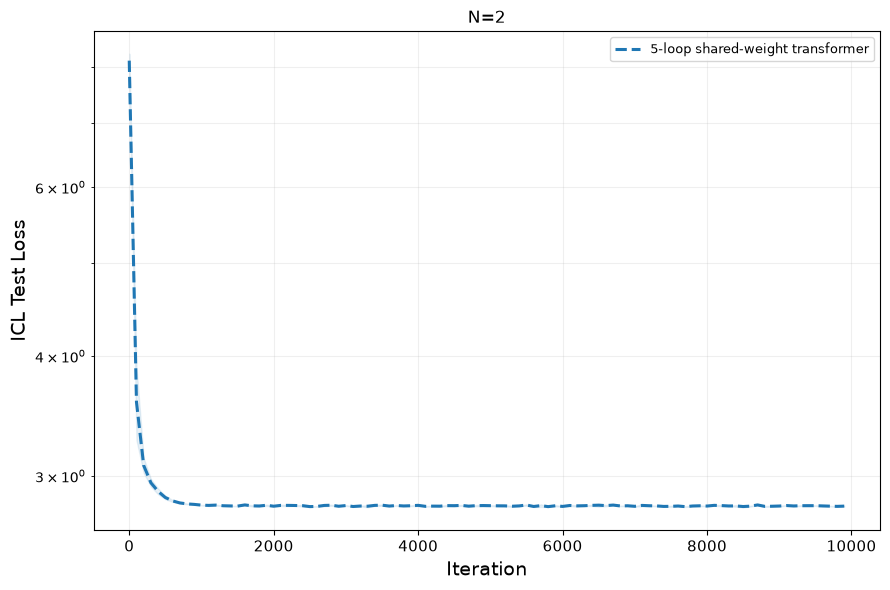

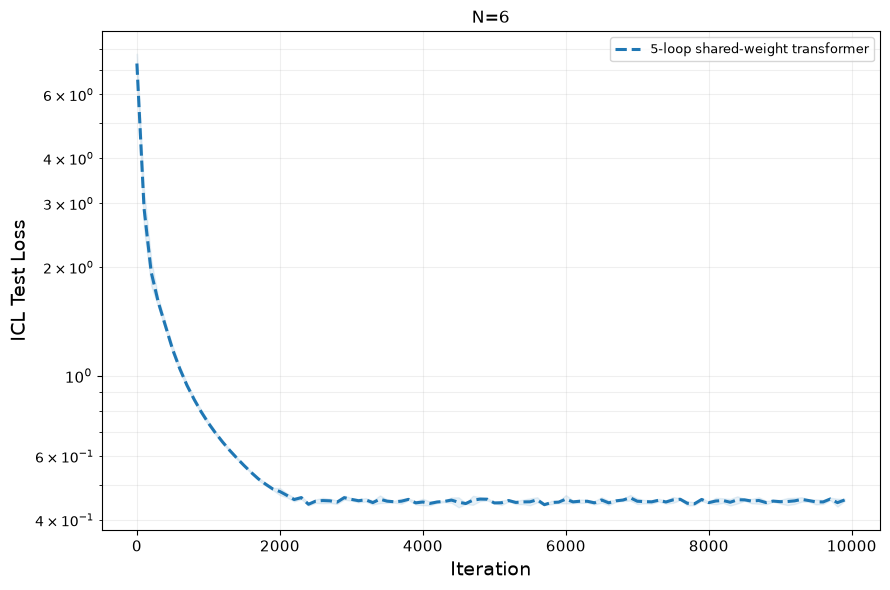

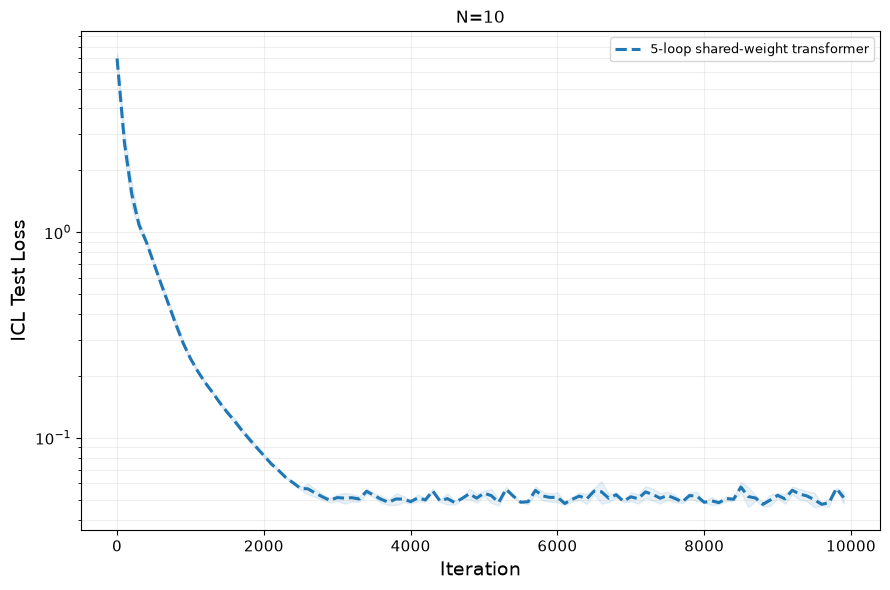

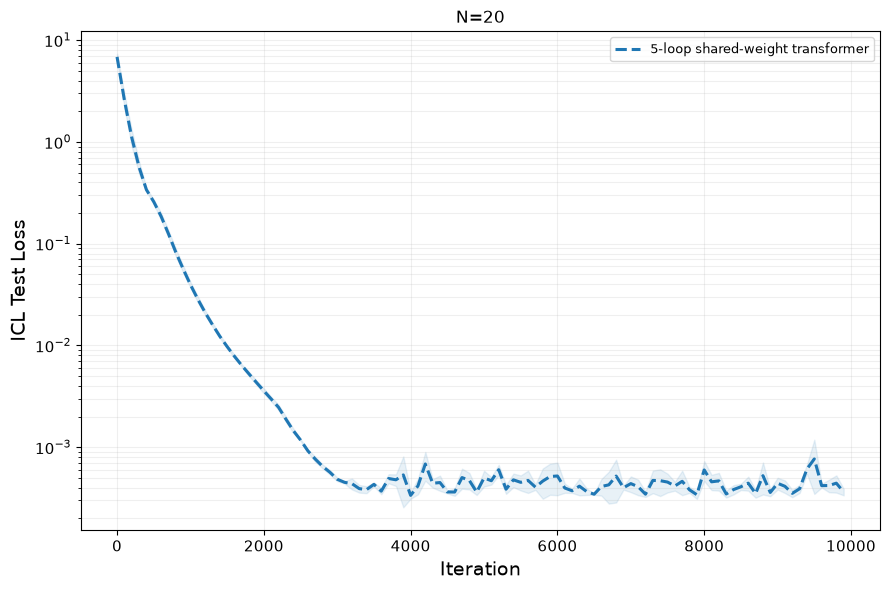

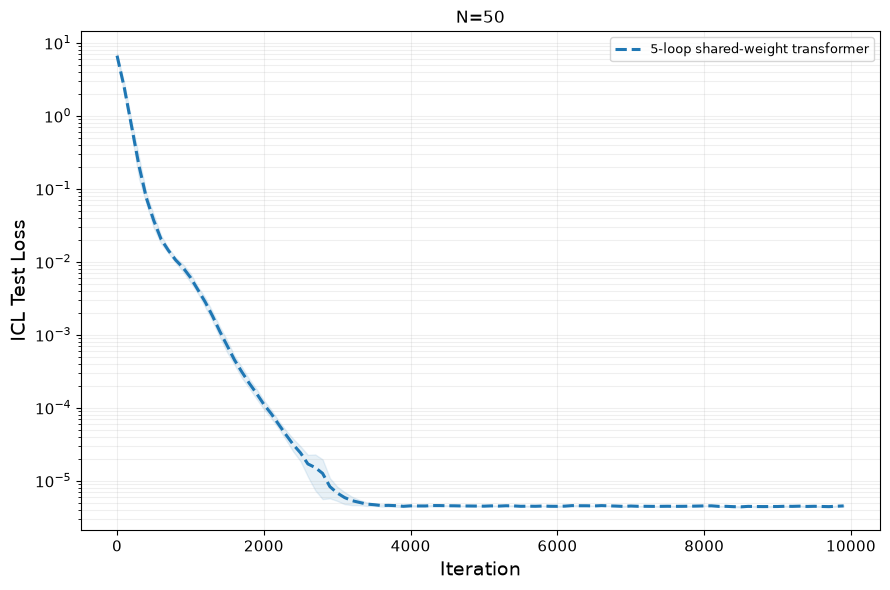

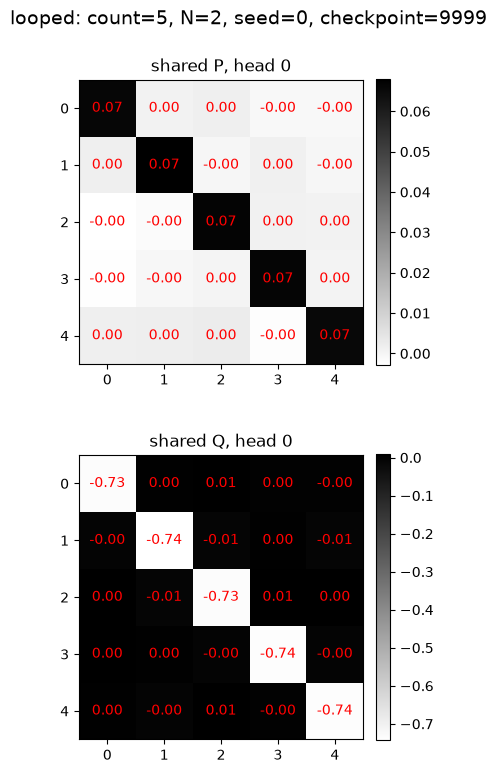

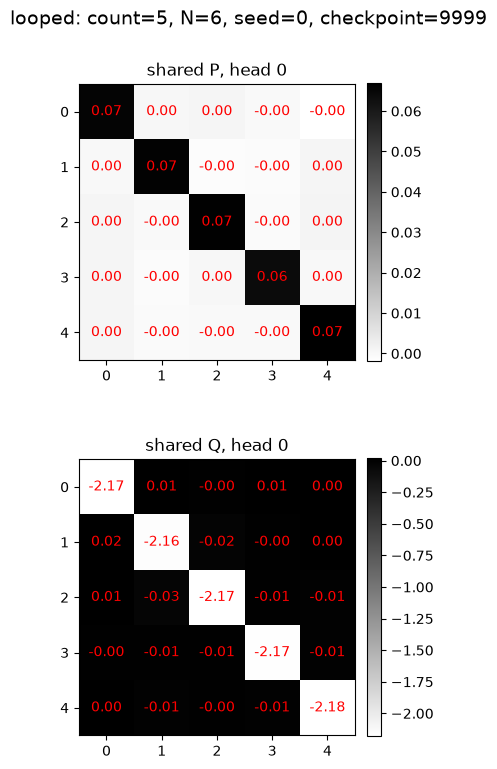

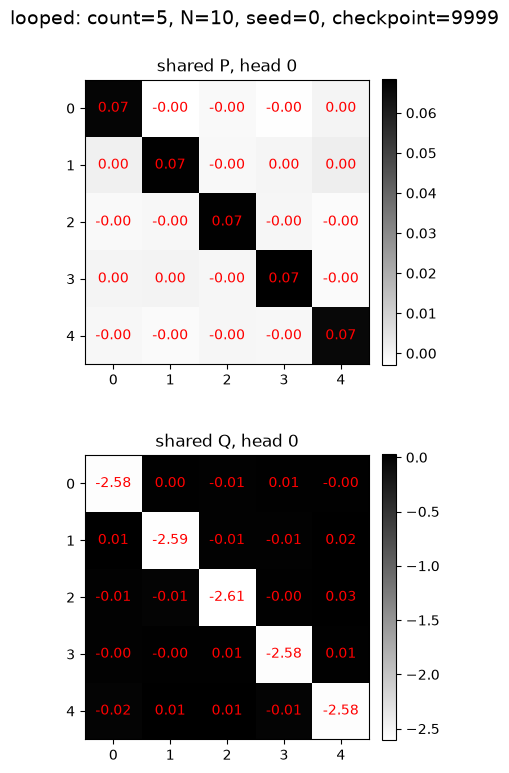

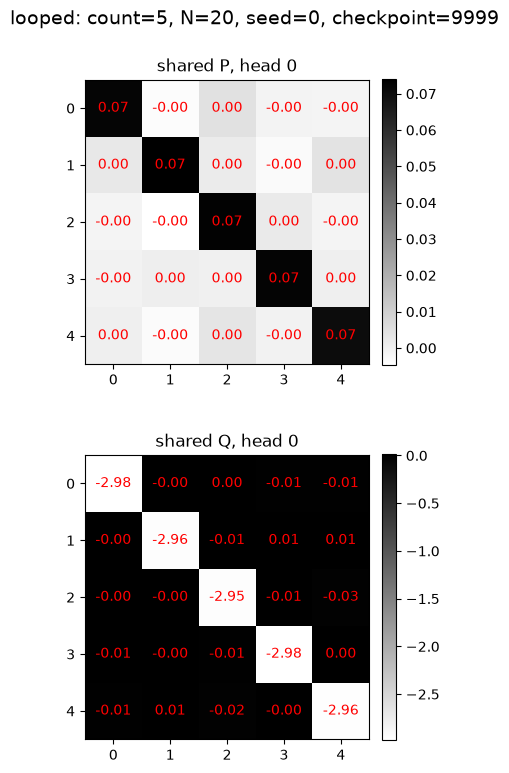

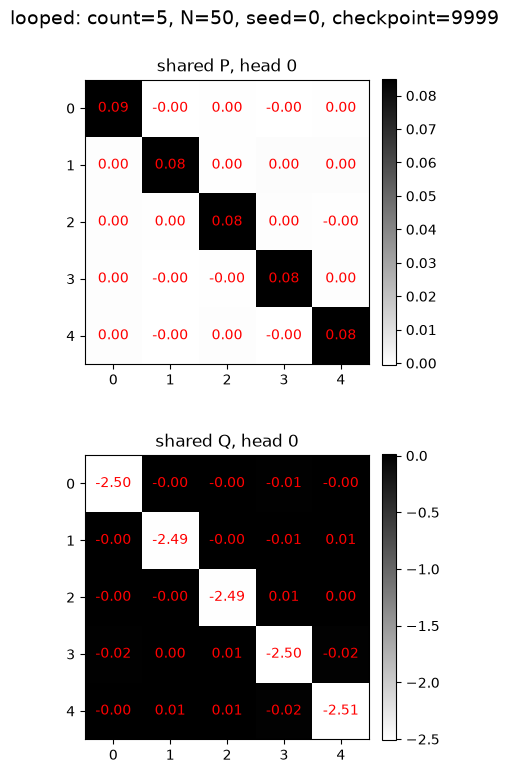

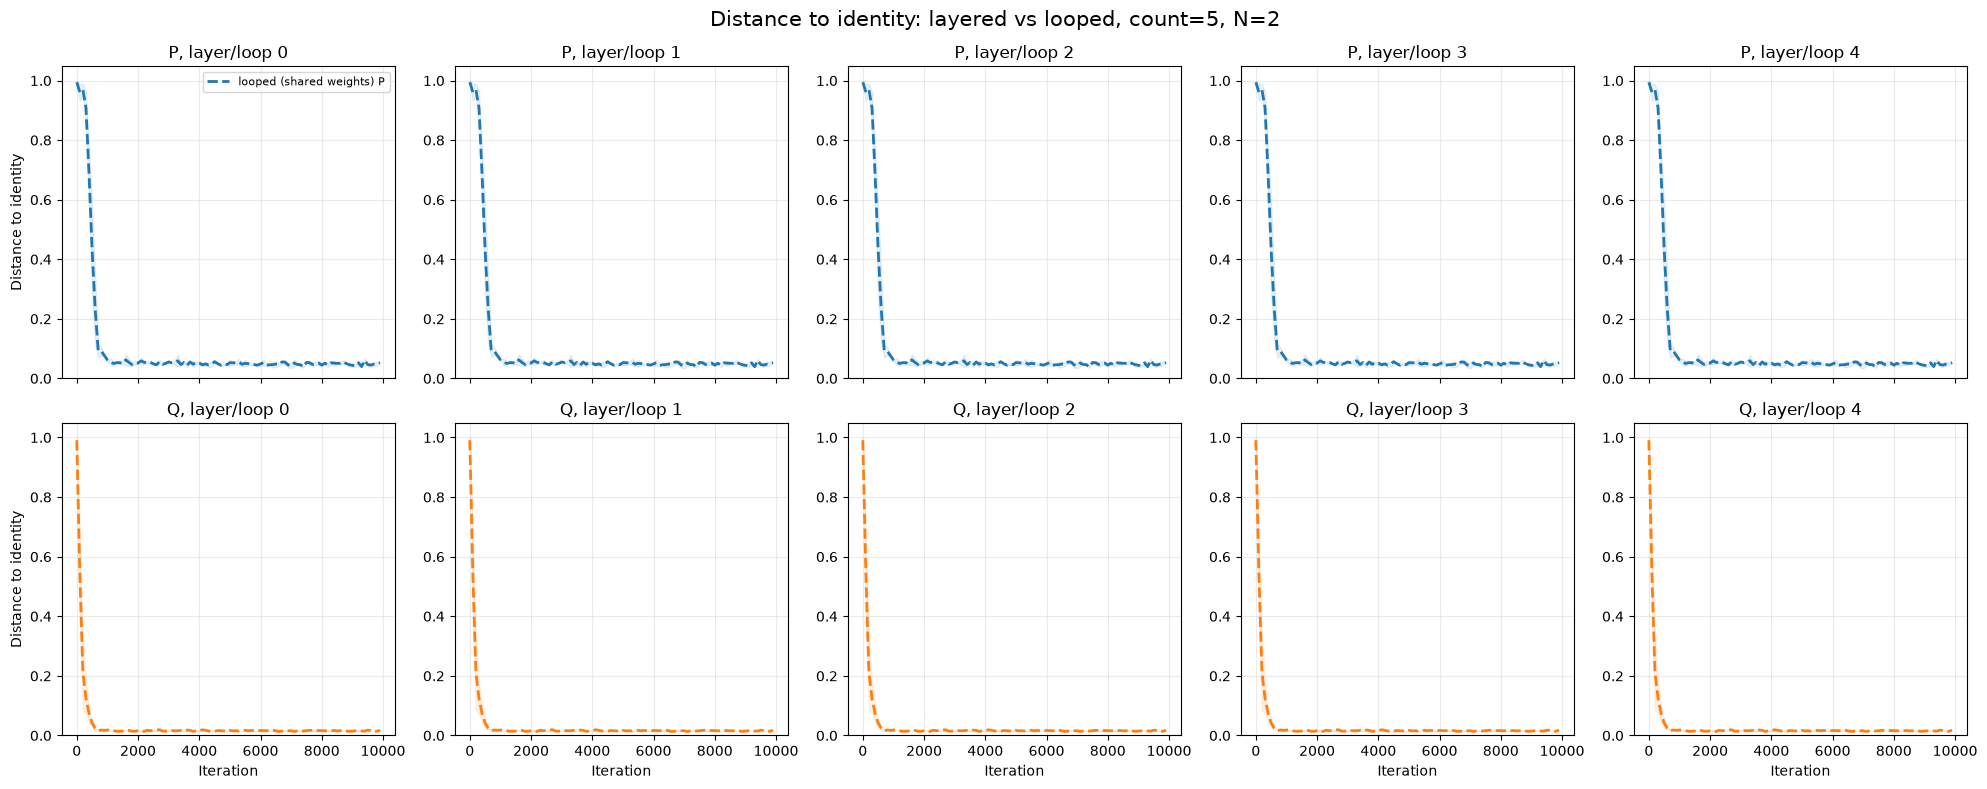

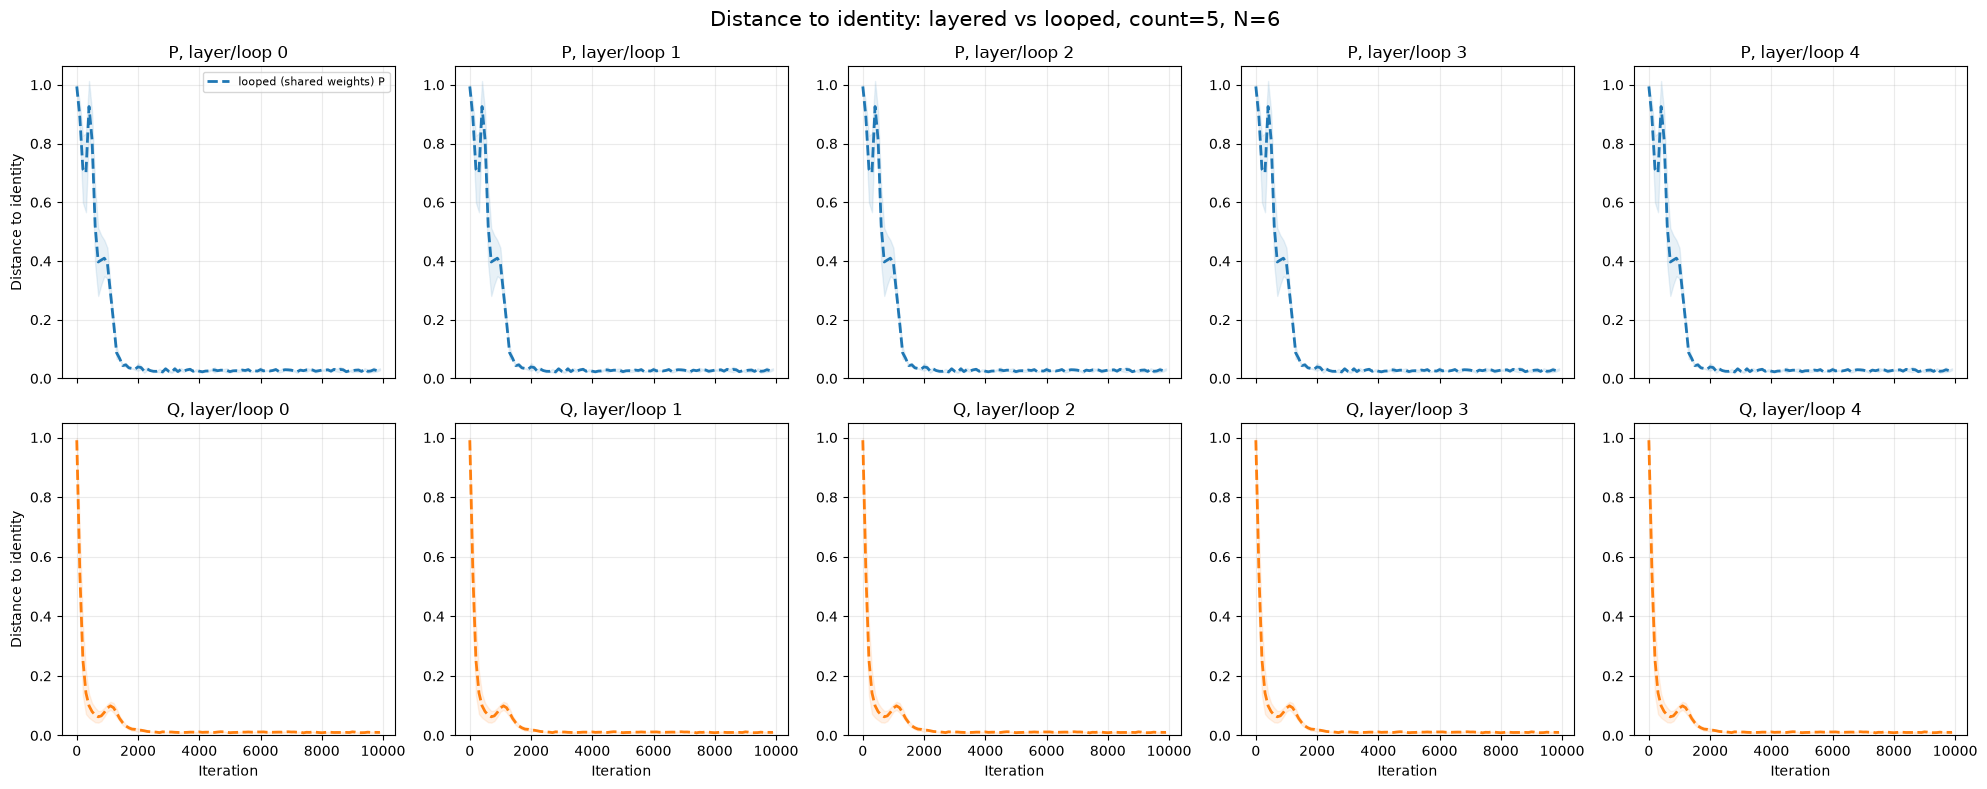

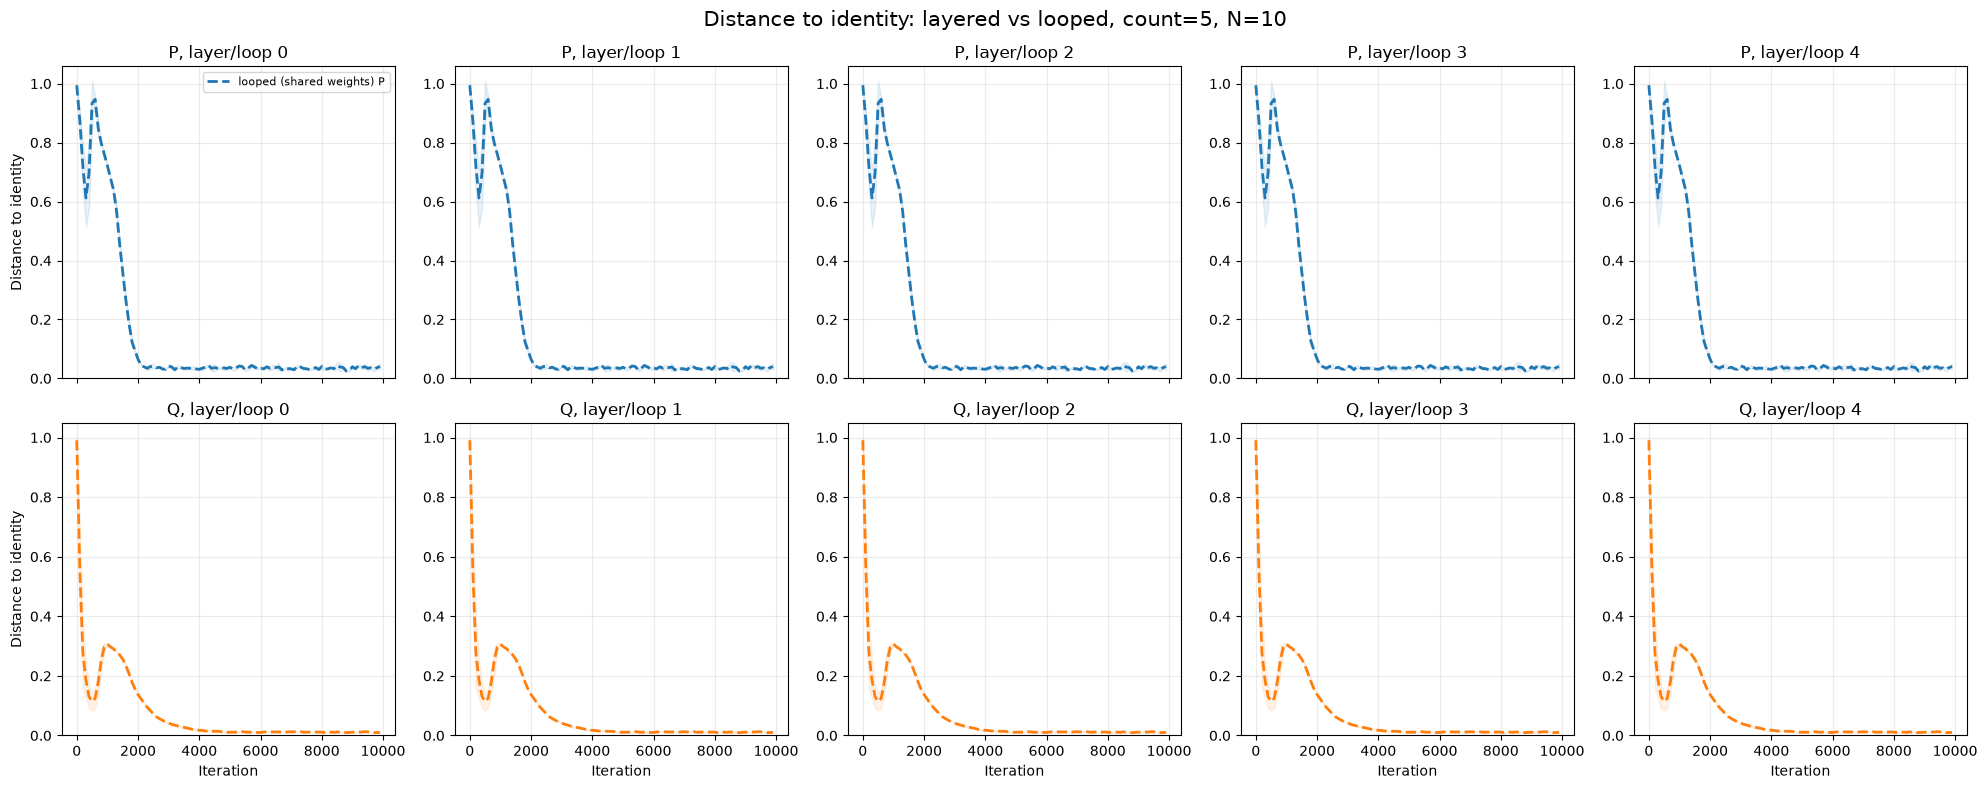

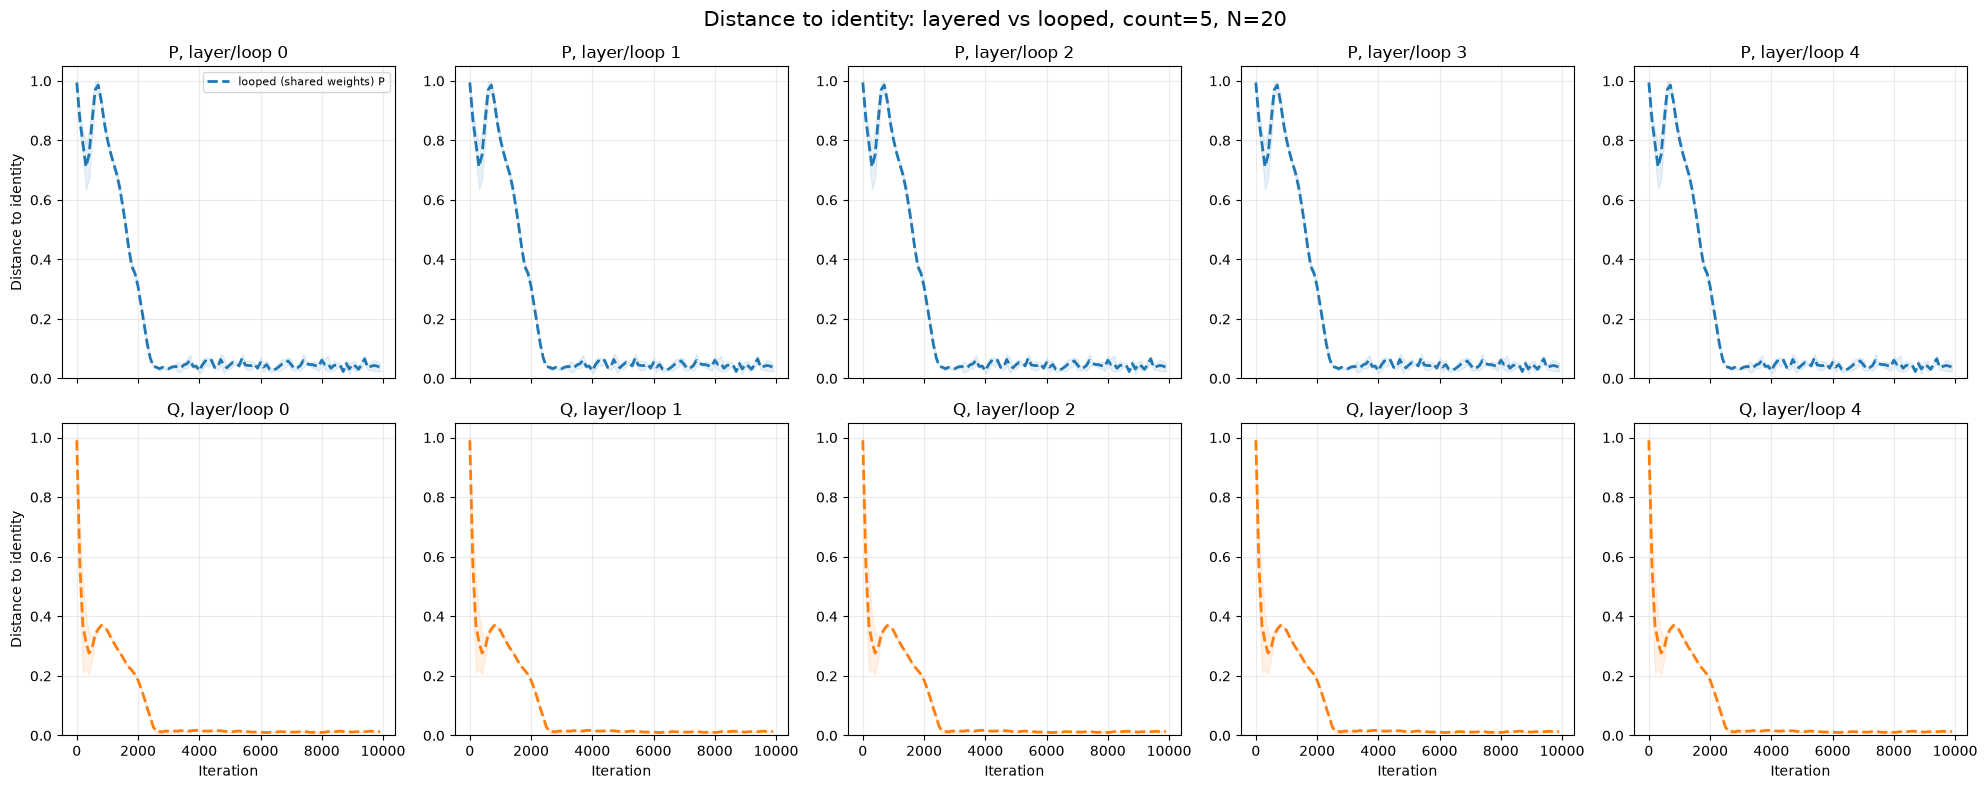

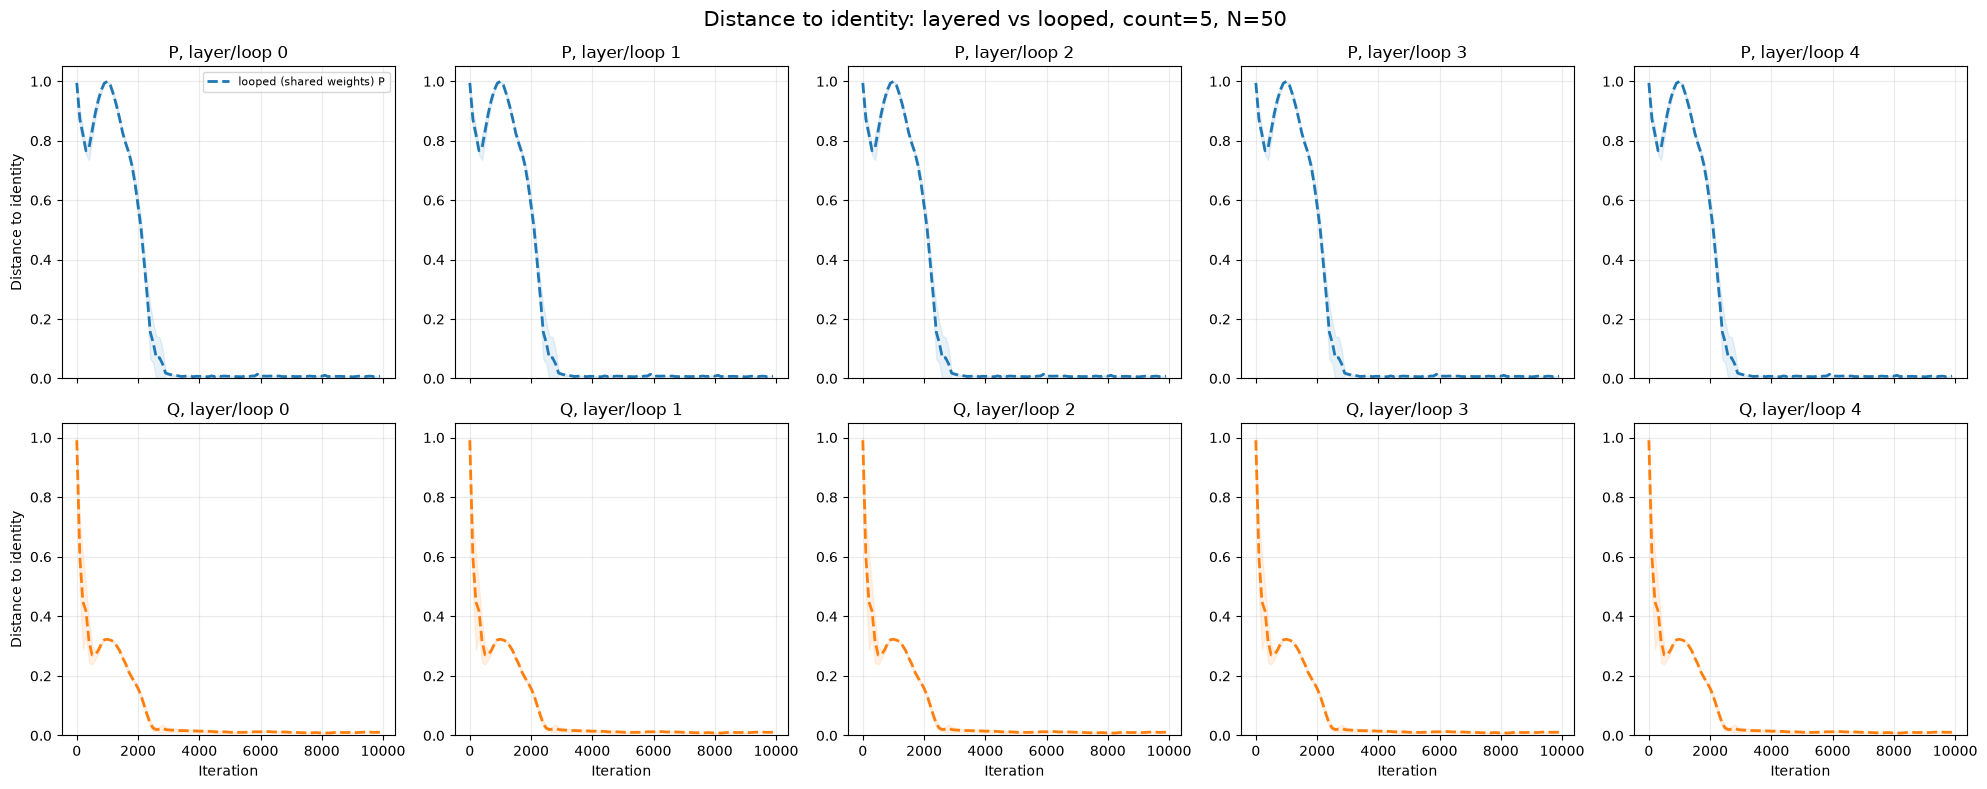

In [ ]:
# Figure 1 computations: looped transformers across context lengths.
f1_seeds = [0, 1, 2]
fig2_N_values = [2, 6, 10, 20, 50]
f1_loop_counts = [5]
f1_model_types = ['looped']
f1_filename = cur_dir + '/figure_one_looped_{}.pth'.format(d)
f1_fig_dir = os.path.join('figures', 'figure_one')
os.makedirs(f1_fig_dir, exist_ok=True)

f1_hist = run_experiment_suite(
    f1_seeds, f1_loop_counts, f1_model_types, f1_filename, context_lengths=fig2_N_values)
f1_loss = compute_loss_dict(f1_hist)
f1_dist = compute_dist_dict(f1_hist, iterations, n_head, hist_stride=hist_stride)

In [ ]:
# Figure 1 plots, immediately following the computation cell.
plot_loss_curves(
    f1_loss,
    f1_loop_counts,
    f1_model_types,
    iterations,
    fig_dir=f1_fig_dir,
    filename='figure_one_test_loss.pdf',
)
plot_parameter_matrices(
    f1_hist,
    f1_seeds[0],
    f1_loop_counts,
    f1_model_types,
    n_head,
    hist_stride=hist_stride,
    fig_dir=f1_fig_dir,
)
plot_dist_to_identity(
    f1_dist,
    f1_loop_counts,
    iterations,
    fig_dir=f1_fig_dir,
)

In [30]:
# Train on the notebook's standard identity-covariance data, then evaluate on
# the adjusted (rotated and rescaled) covariate distribution.
# Reuse run_experiment_suite, compute_loss_dict, and compute_dist_dict.

oos_seeds = [0, 1, 2]
oos_counts = [2, 5]
oos_model_types = ['looped']
oos_fig_dir = os.path.join('figures', 'identity_train_adjusted_test')
os.makedirs(oos_fig_dir, exist_ok=True)
oos_filename = os.path.join(cur_dir, f'identity_train_adjusted_test_N{N}_d{d}.pth')

# Fixed test-time covariance Sigma = U D^2 U^T; training remains unchanged
# and uses generate_data without U,D, i.e. identity covariance.
if d != 5:
    raise ValueError('This covariance setup is defined for d=5.')
torch.manual_seed(1234)
rotation_seed_matrix = (2 * torch.rand(d, d, device=device)) - 1
U_test = torch.linalg.svd(rotation_seed_matrix, full_matrices=True).U
D_test = torch.diag(torch.tensor([1, 1, 0.5, 0.25, 1], device=device))

# Train 2/5-loop transformers with the existing training routine.
oos_hist_dict = run_experiment_suite(
    oos_seeds,
    oos_counts,
    oos_model_types,
    oos_filename,
    context_lengths=[N],
)

# Compute test loss versus training iteration and parameter distances before plotting.
oos_loss_dict = compute_loss_dict(
    oos_hist_dict,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)
oos_iterations = np.arange(0, max_iters, stride)
oos_dist_dict = compute_dist_dict(
    oos_hist_dict,
    oos_iterations,
    n_head,
    hist_stride=hist_stride,
)

torch.save(
    {
        'hist_dict': oos_hist_dict,
        'loss_dict': oos_loss_dict,
        'distance_dict': oos_dist_dict,
        'U_test': U_test.detach().cpu(),
        'D_test': D_test.detach().cpu(),
        'seeds': oos_seeds,
        'counts': oos_counts,
        'model_types': oos_model_types,
        'context_length': N,
    },
    os.path.join(cur_dir, f'identity_train_adjusted_test_N{N}_d{d}_results.pth'),
)
print(f'Saved adjusted-distribution experiment results in {oos_fig_dir} and {cur_dir}.')

Run 1/6: seed=0, count=2, type=looped, N=10
iter 0 | Loss: 5.184084415435791 | time: 0.00932931900024414 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.008291482925415039 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.007063865661621094 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.007478952407836914 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.007328033447265625 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.0065577030181884766 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.0051670074462890625 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.004639387130737305 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.004691600799560547 | gradnorm: 1.5670084953308105
iter 500 | Loss: 1.4401650428771973 | time: 0.004064083099365234 | gradnorm: 0.8317627906799316
iter 600 | Loss: 1.

In [11]:
def plot_loop_loss_curves(loop_loss_dict, n_layers_loops, loop_counts=None,
                         fig_dir='figures', filename='looped_test_loss_vs_loops.pdf',
                         seeds=None, log_scale=True, figsize=(9, 6)):
    """Plot ICL test loss versus inference loop count for looped-model checkpoints.

    `loop_loss_dict` maps each run key (seed, trained loop count, model type,
    context length) to a vector whose position k - 1 contains the loss using k
    loops. Pass looped-model runs only. Curves average over seeds for each
    trained loop count and context length.
    """
    stem, ext = os.path.splitext(filename)
    palette = plt.get_cmap('tab10')
    colors = {
        count: palette(index % 10)
        for index, count in enumerate(n_layers_loops)
    }

    context_lengths = sorted({key[3] for key in loop_loss_dict})
    for context_length in context_lengths:
        fig, ax = plt.subplots(1, 1, figsize=figsize)

        for count in n_layers_loops:
            run_keys = [
                key for key in loop_loss_dict
                if key[1] == count and key[3] == context_length
                and (seeds is None or key[0] in seeds)
            ]
            if not run_keys:
                continue

            run_losses = torch.stack([loop_loss_dict[key].detach().cpu() for key in run_keys])
            valid = torch.isfinite(run_losses)
            n_valid = valid.sum(dim=0)
            safe_losses = torch.where(valid, run_losses, torch.zeros_like(run_losses))
            mean_loss = safe_losses.sum(dim=0) / n_valid.clamp_min(1)
            mean_loss[n_valid == 0] = float('nan')
            variance = torch.where(
                valid,
                (run_losses - mean_loss.unsqueeze(0)) ** 2,
                torch.zeros_like(run_losses),
            ).sum(dim=0) / n_valid.clamp_min(1)
            std_loss = variance.sqrt()

            x_values = np.arange(1, run_losses.shape[1] + 1)
            if loop_counts is not None:
                selected = [
                    loop_count for loop_count in loop_counts
                    if 1 <= loop_count <= run_losses.shape[1]
                ]
                indices = torch.tensor([loop_count - 1 for loop_count in selected])
                x_values = np.asarray(selected)
                mean_loss = mean_loss[indices]
                std_loss = std_loss[indices]
                n_valid = n_valid[indices]

            ax.plot(
                x_values, mean_loss.numpy(), color=colors[count], marker='o',
                lw=2.2, label=f'looping (l=1, loop={count})',
            )
            multiple = n_valid > 1
            lower = torch.where(multiple, mean_loss - std_loss, torch.nan)
            upper = torch.where(multiple, mean_loss + std_loss, torch.nan)
            ax.fill_between(
                x_values, lower.numpy(), upper.numpy(),
                color=colors[count], alpha=0.10,
            )

        ax.set_title(f'N={context_length}')
        ax.set_xlabel('Number of loops', fontsize=14)
        ax.set_ylabel('ICL Test Loss', fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=11)
        if log_scale:
            ax.set_yscale('log')
        ax.legend(fontsize=9)
        ax.grid(True, which='both', alpha=0.2)
        fig.tight_layout()
        fig.savefig(os.path.join(fig_dir, f'{stem}_N{context_length}{ext}'), dpi=600)
        plt.show()

In [12]:
def compute_looped_loss_by_loop_count(hist_dict, max_loops=50, U=None, D=None, test_seed=None,
                                      data_mode: DataMode | None = None):
    """Evaluate each final looped-model checkpoint using 1..max_loops forward loops.

    `hist_dict` should contain looped-model histories only. Each result is a
    length-`max_loops` tensor, where index `k - 1` is the test loss using `k`
    loops, with the checkpoint loaded from that history's final saved value.
    """
    if test_seed is None:
        test_seed = TEST_SEED

    loss_dict = {}
    for key, history in hist_dict.items():
        seed, trained_loop_count, _, context_length = key[:4]
        run_mode = data_mode if data_mode is not None else (key[4] if len(key) > 4 else normal_data_mode)
        if not history:
            loss_dict[key] = torch.full((max_loops,), float('nan'))
            continue

        final_snapshot = history[-1]
        losses = torch.full((max_loops,), float('nan'))
        if not torch.isfinite(final_snapshot).all():
            loss_dict[key] = losses
            continue

        np.random.seed(test_seed)
        torch.manual_seed(test_seed)
        Z, y = generate_data(run_mode, context_length, d, B, U=U, D=D)
        Z = Z.to(device)
        y = y.to(device)

        # Looped models share one parameter block; change only the number of
        # times that block is applied at inference.
        model = Transformer_F_Looped(1, n_head, d, var).to(device)
        with torch.no_grad():
            model.allparam.copy_(final_snapshot.to(device))
            for loop_count in range(1, max_loops + 1):
                model.n_loop = loop_count
                losses[loop_count - 1] = in_context_loss(model, Z, y).item()

        loss_dict[key] = losses

    return loss_dict

In [33]:
# Evaluate final looped checkpoints with 1 through 50 inference loops.
oos_looped_hist_dict = {
    key: history
    for key, history in oos_hist_dict.items()
    if key[2] == 'looped'
}
oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=50,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

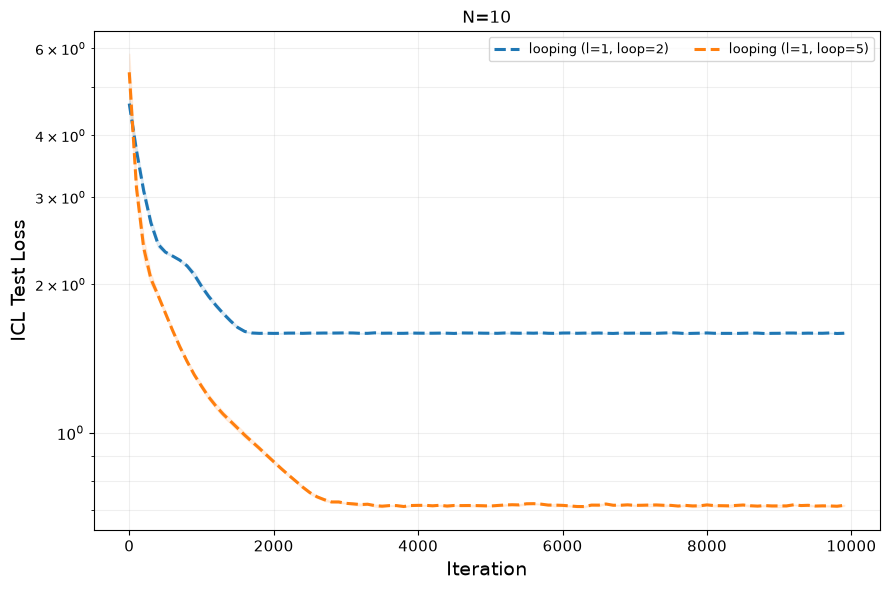

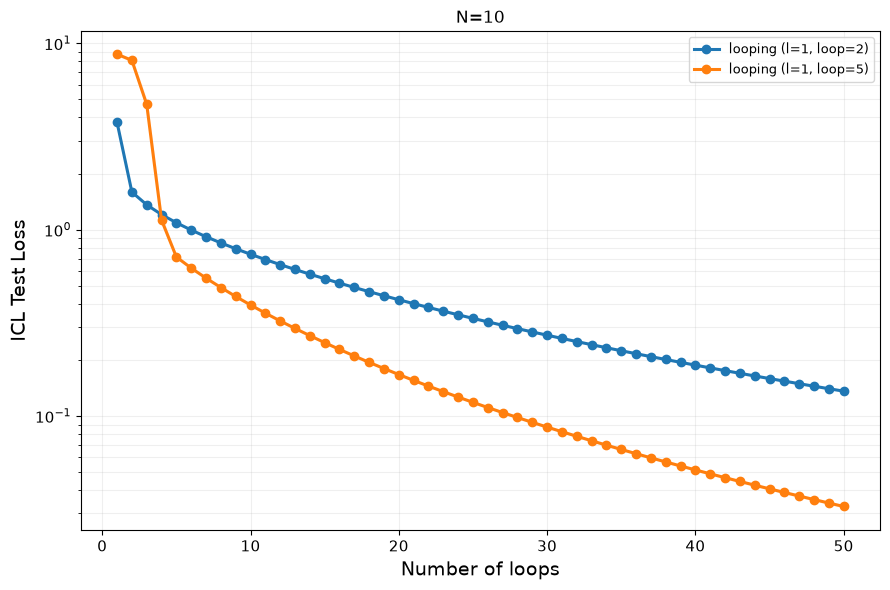

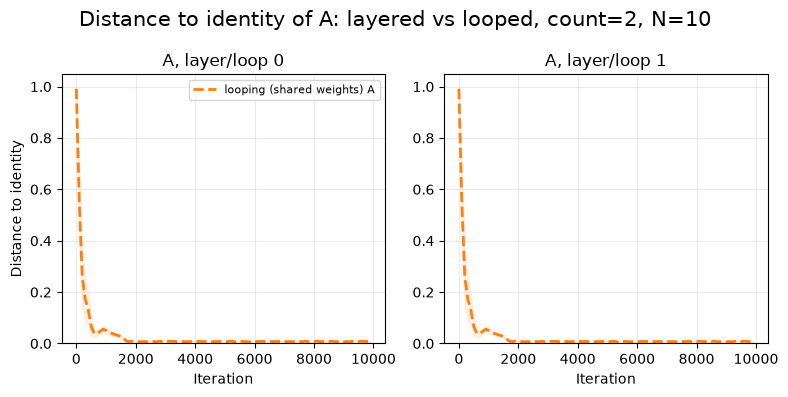

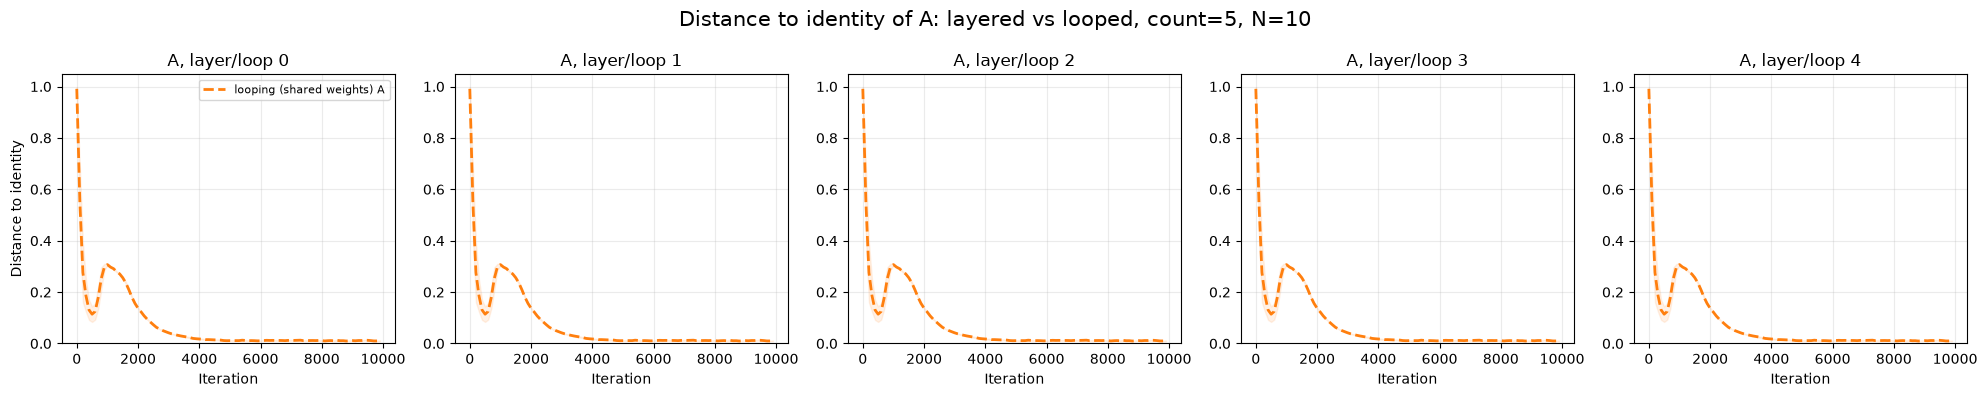

In [39]:
# Plot the adjusted-distribution test loss by training iteration.
plot_loss_curves(
    oos_loss_dict,
    oos_counts,
    oos_model_types,
    oos_iterations,
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_test_loss.pdf',
)

# Plot looped-model test loss against the number of inference loops (1..50).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 51),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_loop_count.pdf',
)

# Plot distance-to-identity for the trained looped-model parameters.
plot_dist_to_identity(
    oos_dist_dict,
    oos_counts,
    oos_iterations,
    fig_dir=oos_fig_dir,
)

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

## Distribution shift: high-condition-number test data

Train layered and shared-weight looped transformers on standard Gaussian regression tasks with $d=5$ and $N=10$. Evaluate the same checkpoints on fixed, independent standard and transformed test batches. The transformed population covariance has condition number $1000$; individual context Gram matrices have varying condition numbers.

Training and test batch sizes, optimization, initialization, and checkpoint settings are shared with the first experiment. Training uses the repository's clipped `in_context_loss`; the plotted held-out loss is **unclipped** mean squared prediction error. Curves show the mean and standard deviation across training seeds; nonfinite losses are omitted and reported. First run the import, problem-parameter, `run_experiment_suite`, `compute_loss_dict`, and `plot_loss_curves` definition cells above, then run this section in order. Rerun the problem-parameter cell if another experiment has changed its settings.

In [24]:
import math

# Match the first experiment's seeds and architectures, using the requested sizes.
hc_seeds = [0, 1, 2]
hc_sizes = [1, 2, 5, 10]
hc_model_types = ['looped']

# Only the test distribution differs from the first experiment.
hc_cov_condition = 10000.0
hc_rotation_seed = 2000

if N != 10 or d != 5:
    raise ValueError('Run the first experiment\'s problem-parameter cell to set N=10 and d=5.')
print(f'High-condition experiment device: {device}')

High-condition experiment device: cuda


In [92]:
# Reuse the first experiment's training and evaluation settings.
hc_iterations = np.arange(0, max_iters, stride)
hc_fig_dir = os.path.join('figures', 'high_condition_test')
os.makedirs(hc_fig_dir, exist_ok=True)
hc_history_file = os.path.join(cur_dir, 'high_condition_N10_d5_histories.pth')
hc_results_file = os.path.join(cur_dir, 'high_condition_N10_d5_results.pth')

# Generate a fixed orthogonal basis by SVD, with a prescribed covariance spectrum.
torch.manual_seed(hc_rotation_seed)

svd_result = torch.linalg.svd(torch.randn(d, d, device=device))

hc_U = svd_result.U
hc_scales = torch.logspace(
    0, -0.5 * math.log10(hc_cov_condition), d, device=device,
)

hc_D = torch.diag(hc_scales)

print(f'Population covariance condition number: {torch.linalg.cond(hc_D).item() ** 2:.1f}')

Population covariance condition number: 10000.0


Updated todo list

For each normal covariate, `generate_data()` starts with $z \sim \mathcal N(0,I)$ and applies

$$
x = U D z.
$$

Here’s each component’s role:

1. **`hc_scales`** contains standard deviations ranging from $1$ down to $1/\sqrt{1000}$. These set the spread of the data in each principal direction.
2. **`hc_D`** places those scales on a diagonal: $D = \operatorname{diag}(\text{hc_scales})$.
3. **`hc_U`** rotates the scaled data. Because $U$ is orthogonal, it changes the directions but not the condition number.

The resulting **population covariance** is

$$
\Sigma = \operatorname{Cov}(x) = U D^2 U^\top.
$$

Its eigenvalues are the squared entries of `hc_scales`. Therefore, its condition number is

$$
\kappa(\Sigma)
= \frac{\text{largest eigenvalue}}{\text{smallest eigenvalue}}
= \frac{1^2}{(1/\sqrt{1000})^2}
= 1000.
$$

The fixed value applies to the **population covariance**. Each sampled context has only `N = 10` examples, so its empirical covariance will generally have a different condition number.

In [25]:
def compute_data_condition_numbers(Z):
    """Return per-task condition numbers of X and its uncentered Gram matrix X.T @ X.

    Z is the prompt returned by generate_data: the last row is the query and
    the last column contains labels. Singular Gram matrices have condition inf.
    """
    if Z.ndim != 3 or Z.shape[1] < 2 or Z.shape[2] < 2:
        raise ValueError('Expected Z with shape (B, N + 1, d + 1), N >= 1, d >= 1.')

    X = Z[:, :-1, :-1].double()
    singular_values = torch.linalg.svdvals(X)
    largest, smallest = singular_values[:, 0], singular_values[:, -1]
    tolerance = torch.finfo(X.dtype).eps * max(X.shape[-2:]) * largest
    condition_X = torch.where(smallest > tolerance, largest / smallest, float('inf'))
    if X.shape[-2] < X.shape[-1]:
        condition_gram = torch.full_like(condition_X, float('inf'))
    else:
        condition_gram = condition_X.square()
    return condition_X, condition_gram


# Examine a reproducible batch from the high-condition test distribution.
torch.manual_seed(TEST_SEED)
hc_Z, _ = generate_data(normal_data_mode, N, d, B, U=hc_U, D=hc_D)
hc_data_conditions, hc_gram_conditions = compute_data_condition_numbers(hc_Z)
print(f'Median context X condition: {hc_data_conditions.median().item():.1f}')
print(f'Median context Gram condition: {hc_gram_conditions.median().item():.1f}')

NameError: name 'hc_U' is not defined

In [75]:
# Train on standard normal data using the existing training helper.
hc_hist_dict = run_experiment_suite(
    seeds=hc_seeds,
    n_layers_loops=hc_sizes,
    model_types=hc_model_types,
    filename=hc_history_file,
    context_lengths=[N],
)

Run 1/4: seed=0, count=1, type=looped, N=10
iter 0 | Loss: 4.782515525817871 | time: 0.0069239139556884766 | gradnorm: 3.1331946849823
iter 1 | Loss: 4.460882663726807 | time: 0.005681753158569336 | gradnorm: 3.160719156265259
iter 2 | Loss: 4.659054756164551 | time: 0.006200075149536133 | gradnorm: 3.2489049434661865
iter 3 | Loss: 4.460082054138184 | time: 0.005029439926147461 | gradnorm: 3.143481969833374
iter 4 | Loss: 4.543564319610596 | time: 0.004951953887939453 | gradnorm: 3.2081918716430664
iter 100 | Loss: 3.836466073989868 | time: 0.002681732177734375 | gradnorm: 3.024074077606201
iter 200 | Loss: 3.3473775386810303 | time: 0.0026710033416748047 | gradnorm: 2.7464020252227783
iter 300 | Loss: 2.8352458477020264 | time: 0.0026853084564208984 | gradnorm: 2.3970413208007812
iter 400 | Loss: 2.3862922191619873 | time: 0.0027616024017333984 | gradnorm: 1.8073077201843262
iter 500 | Loss: 2.0302138328552246 | time: 0.002690553665161133 | gradnorm: 1.1721309423446655
iter 600 | Los

In [ ]:
# Compare both distributions using the first experiment's fixed test seed and batch size.
hc_standard_loss = compute_loss_dict(
    hc_hist_dict, test_seed=TEST_SEED
)
hc_shifted_loss = compute_loss_dict(
    hc_hist_dict, U=hc_U, D=hc_D, test_seed=TEST_SEED
)

# Verify the actual condition numbers of the held-out context matrices.
torch.manual_seed(TEST_SEED)
hc_Z, _ = generate_data(normal_data_mode, N, d, B, U=hc_U, D=hc_D)
hc_data_conditions, hc_gram_conditions = compute_data_condition_numbers(hc_Z)
print(f'Median empirical context X condition: {hc_data_conditions.median().item():.1f}')
print(f'Median empirical context Gram condition: {hc_gram_conditions.median().item():.1f}')
for name, losses in [('standard', hc_standard_loss), ('shifted', hc_shifted_loss)]:
    n_nonfinite = sum((~torch.isfinite(values)).sum().item() for values in losses.values())
    print(f'{name} test: {n_nonfinite} missing or nonfinite checkpoint losses')

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head, 'mode': normal_data_mode,
        'shape_k': 0.1, 'alg': alg, 'lr': lr, 'clip_r': clip_r,
        'var': var, 'max_iters': max_iters, 'hist_stride': hist_stride,
        'stride': stride, 'seeds': hc_seeds, 'sizes': hc_sizes,
        'model_types': hc_model_types, 'test_seed': TEST_SEED,
        'cov_condition': hc_cov_condition, 'rotation_seed': hc_rotation_seed,
    },
    'history_file': hc_history_file,
    'standard_loss': hc_standard_loss,
    'shifted_loss': hc_shifted_loss,
    'U': hc_U.cpu(),
    'D': hc_D.cpu(),
    'iterations': hc_iterations,
    'context_gram_conditions': hc_gram_conditions.cpu(),
}, hc_results_file)
print(f'Saved results to {hc_results_file}')

Median empirical context Gram condition: 18412.9
standard test: 0 missing or nonfinite checkpoint losses
shifted test: 0 missing or nonfinite checkpoint losses
Saved results to log/high_condition_N10_d5_results.pth


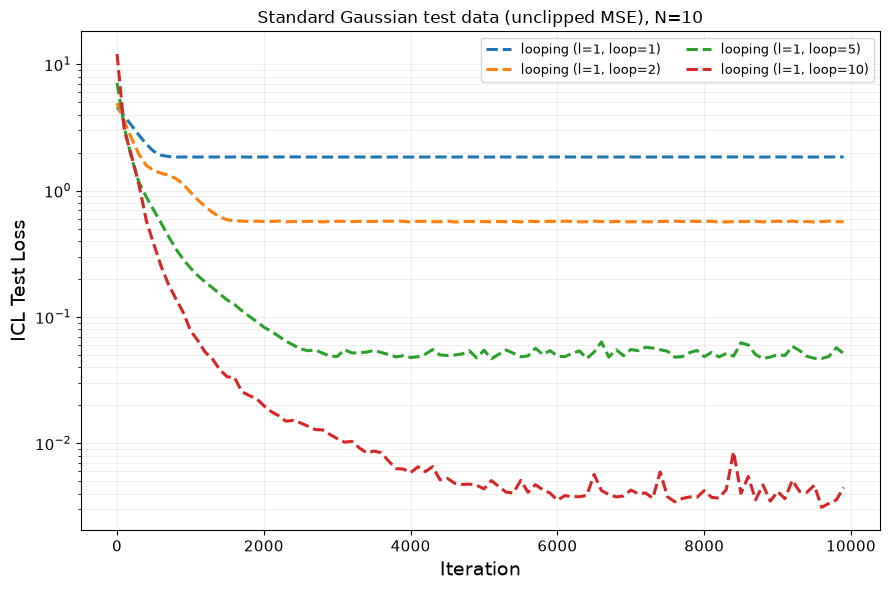

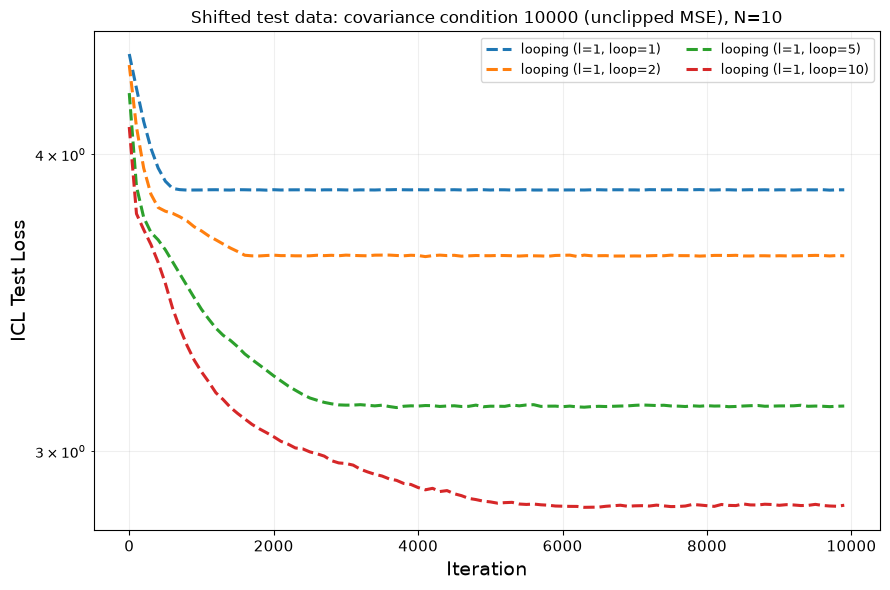

In [77]:
# Plot both test distributions with the existing plotting helper.
plot_loss_curves(
    hc_standard_loss, hc_sizes, hc_model_types, hc_iterations,
    fig_dir=hc_fig_dir, filename='standard_test_loss.pdf',
    title='Standard Gaussian test data (unclipped MSE)',
)
plot_loss_curves(
    hc_shifted_loss, hc_sizes, hc_model_types, hc_iterations,
    fig_dir=hc_fig_dir, filename='high_condition_test_loss.pdf',
    title=f'Shifted test data: covariance condition {hc_cov_condition:.0f} (unclipped MSE)',
)

# Different Data Distributions

Train the shared-weight looped transformers from the first experiment independently on each configured data mode, then evaluate each set of checkpoints on an independently sampled test batch from that same mode. The seeds, loop counts, optimization settings, and model setup match the first experiment; the gamma shape parameter comes from the problem-parameter cell.

In [2]:
# Add data mode as an independent experiment configuration.
gamma_data_mode_low_shape = DataMode("gamma", gamma_shape=0.1, gamma_scale=1)
gamma_data_mode_high_shape = DataMode("gamma", gamma_shape=5, gamma_scale=1)
t_distribution_mode = DataMode("t", t_degrees_freedom=5)

seeds = [0, 1, 2]
loop_counts = [1, 2, 5, 10]
model_types = ['looped']
context_lengths = [N]
data_modes = [normal_data_mode, gamma_data_mode_low_shape, gamma_data_mode_high_shape, t_distribution_mode]
iterations = np.arange(0, max_iters, stride)

gamma_fig_dir = os.path.join('figures', 'data_mode_comparison')
os.makedirs(gamma_fig_dir, exist_ok=True)

gamma_history_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_histories.pth')
gamma_results_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_results.pth')

gamma_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=gamma_history_file,
    context_lengths=context_lengths,
    data_modes=data_modes,
)

gamma_loss_dict = {
    test_data_mode: compute_loss_dict(
        gamma_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in data_modes
}
# Parameter distances depend on the trained checkpoints, not on the test data mode.
gamma_dist_dict = compute_dist_dict(
    gamma_hist_dict, iterations, n_head, hist_stride=hist_stride)


NameError: name 'DataMode' is not defined

Saved data-mode experiment results to log/data_modes_normal_gamma_N10_d5_results.pth


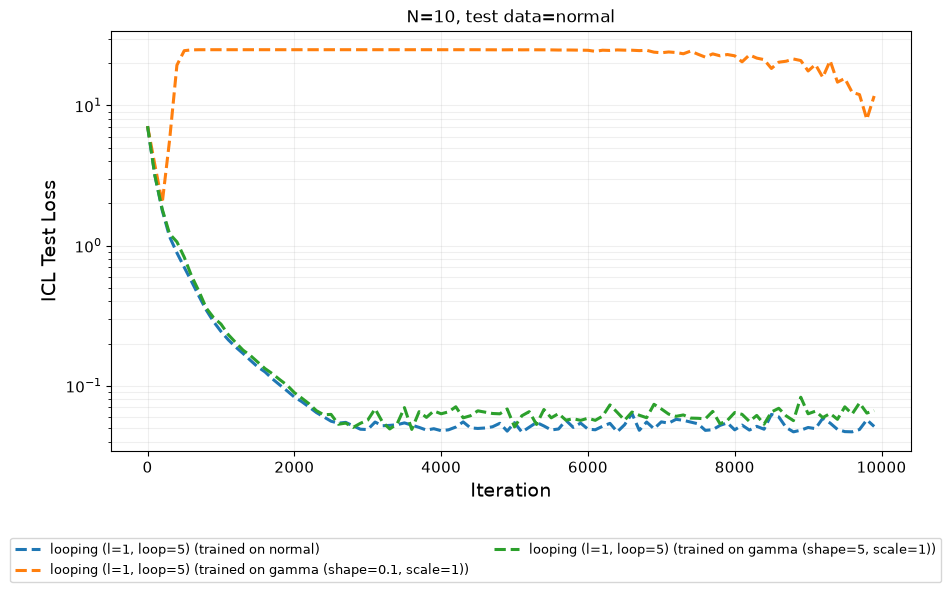

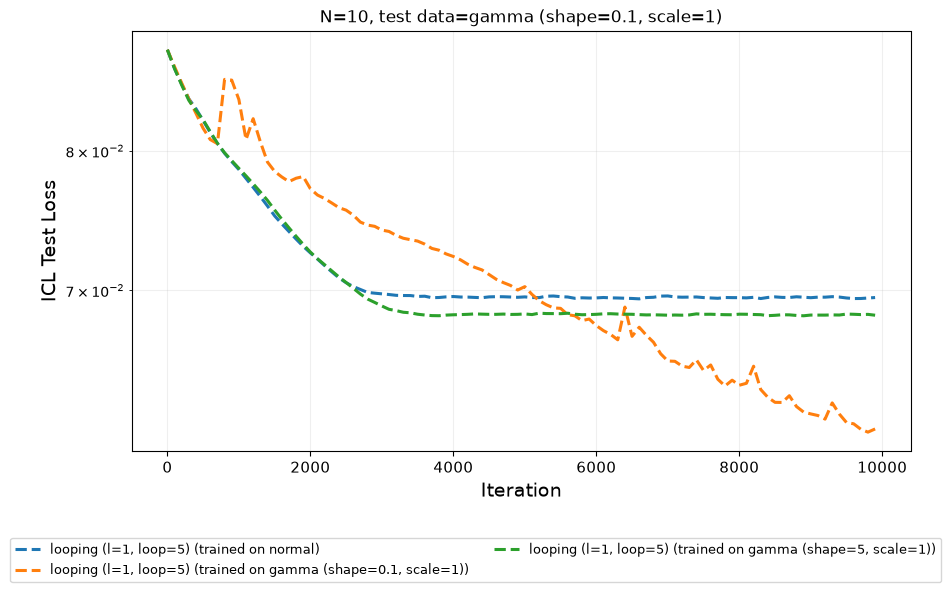

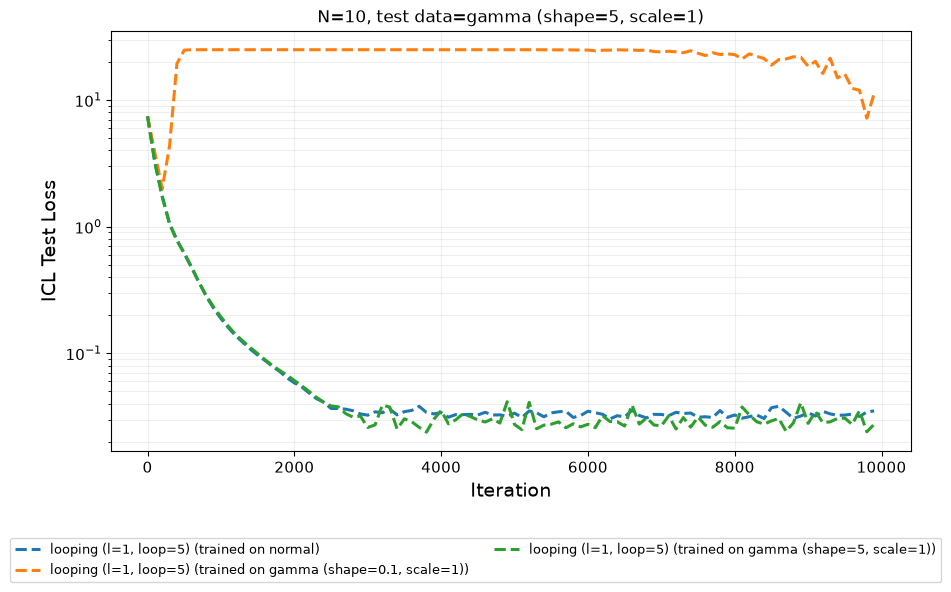

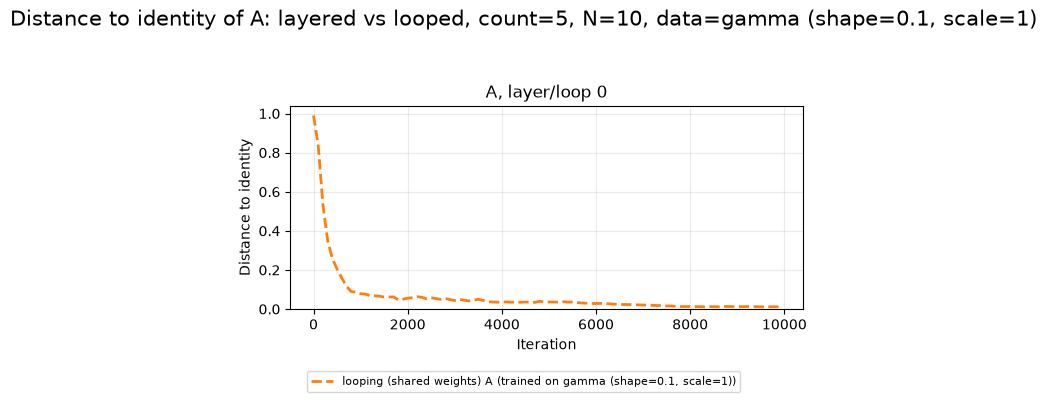

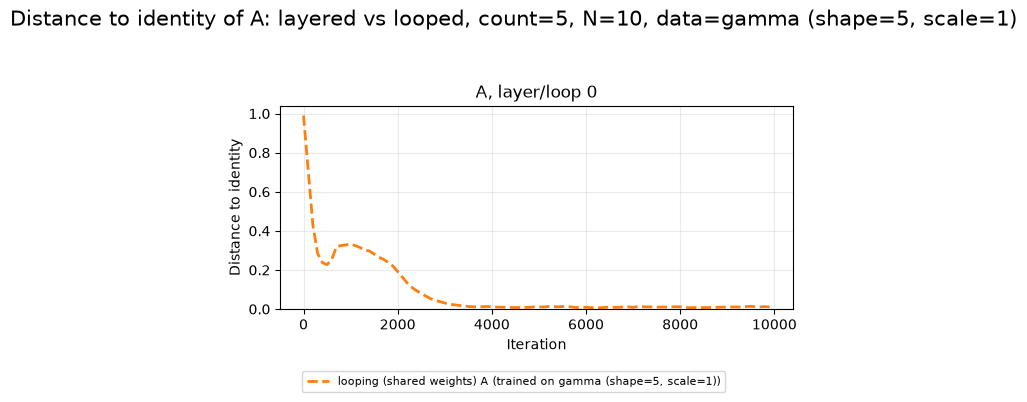

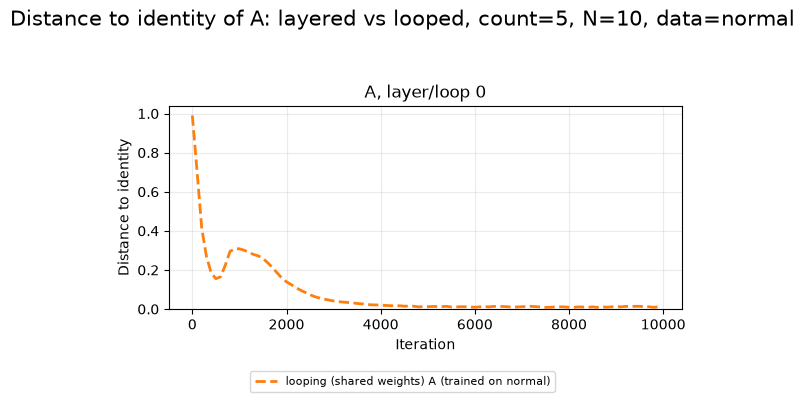

In [23]:
torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': data_modes,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': gamma_history_file,
    'hist_dict': gamma_hist_dict,
    'loss_dict_by_test_mode': gamma_loss_dict,
    'distance_dict': gamma_dist_dict,
    'iterations': iterations,
}, gamma_results_file)
print(f'Saved data-mode experiment results to {gamma_results_file}')

for test_data_mode, loss_dict in gamma_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=gamma_fig_dir, filename='data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    gamma_dist_dict, loop_counts, iterations, fig_dir=gamma_fig_dir,
)
plot_parameter_matrices(
    gamma_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=gamma_fig_dir,
)


# Non-Linear Distribution Test

Train the shared-weight looped transformers independently on normal, ReLU-generated, and MLP-generated data. This mirrors the different-distribution experiment: the same seeds, loop counts, optimization settings, and plots are reused to check whether the training converges and to display the learned parameter trajectories.


In [14]:
relu_data_mode = DataMode("relu")
mlp_data_mode = DataMode("mlp")

seeds = [0]
loop_counts = [2, 5, 10]
model_types = ['looped']
context_lengths = [N]
nonlinear_data_modes = [normal_data_mode, relu_data_mode, mlp_data_mode]
iterations = np.arange(0, max_iters, stride)

nonlinear_fig_dir = os.path.join('figures', 'nonlinear_data_mode_comparison')
os.makedirs(nonlinear_fig_dir, exist_ok=True)

nonlinear_history_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_histories.pth')
nonlinear_results_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_results.pth')

nonlinear_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=nonlinear_history_file,
    context_lengths=context_lengths,
    data_modes=nonlinear_data_modes,
)

nonlinear_loss_dict = {
    test_data_mode: compute_loss_dict(
        nonlinear_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in nonlinear_data_modes
}
nonlinear_dist_dict = compute_dist_dict(
    nonlinear_hist_dict, iterations, n_head, hist_stride=hist_stride)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': nonlinear_data_modes,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': nonlinear_history_file,
    'hist_dict': nonlinear_hist_dict,
    'loss_dict_by_test_mode': nonlinear_loss_dict,
    'distance_dict': nonlinear_dist_dict,
    'iterations': iterations,
}, nonlinear_results_file)
print(f'Saved non-linear data-mode experiment results to {nonlinear_results_file}')

Run 1/9: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None)
iter 0 | Loss: 5.184084415435791 | time: 0.008438587188720703 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.007271766662597656 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.007939815521240234 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.0077419281005859375 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.007574796676635742 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.0052394866943359375 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.006361246109008789 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.00635838508605957 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.004073381423950195 | gradnorm: 1.5670084953308105
iter 500 | Loss: 1.440165

/home/i4sincla/Documents/projects/cs-886/looped-transformers-gradient-descent/.env/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


iter 0 | Loss: 22.86710548400879 | time: 2.4036972522735596 | gradnorm: 20.595840454101562
iter 1 | Loss: 11.965705871582031 | time: 0.007816553115844727 | gradnorm: 82.57300567626953
iter 2 | Loss: 23.663801193237305 | time: 0.008239269256591797 | gradnorm: 134.87745666503906
iter 3 | Loss: 22.301246643066406 | time: 0.008141279220581055 | gradnorm: 99.23126220703125
iter 4 | Loss: 18.46664047241211 | time: 0.008145332336425781 | gradnorm: 49.724632263183594
iter 100 | Loss: 15.3301362991333 | time: 0.009746551513671875 | gradnorm: 77.91268920898438
iter 200 | Loss: 6.315530776977539 | time: 0.009783744812011719 | gradnorm: 40.39655685424805
iter 300 | Loss: 7.328475475311279 | time: 0.009759187698364258 | gradnorm: 186.7466278076172
iter 400 | Loss: 7.566160678863525 | time: 0.006357908248901367 | gradnorm: 138.25709533691406
iter 500 | Loss: 6.108644008636475 | time: 0.006046772003173828 | gradnorm: 53.359413146972656
iter 600 | Loss: 6.221442699432373 | time: 0.006385087966918945 |

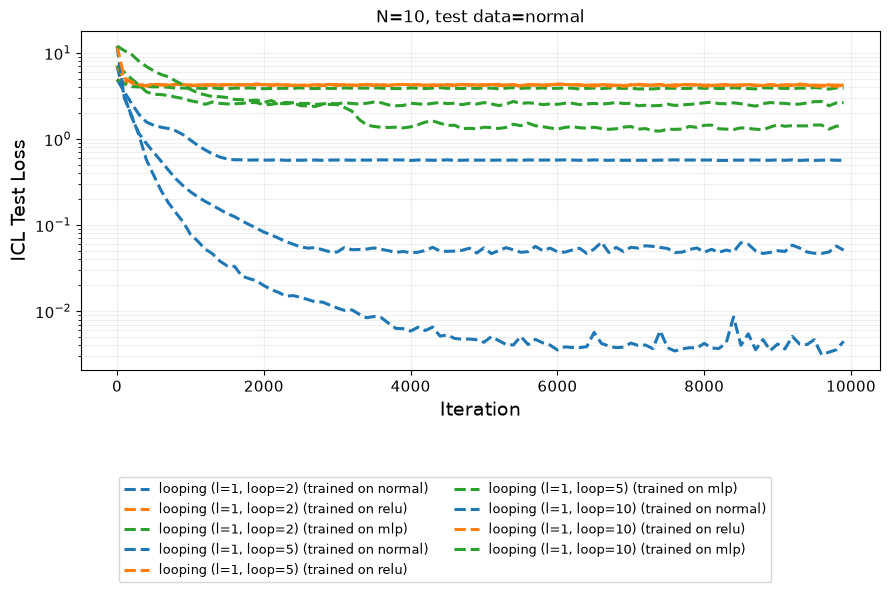

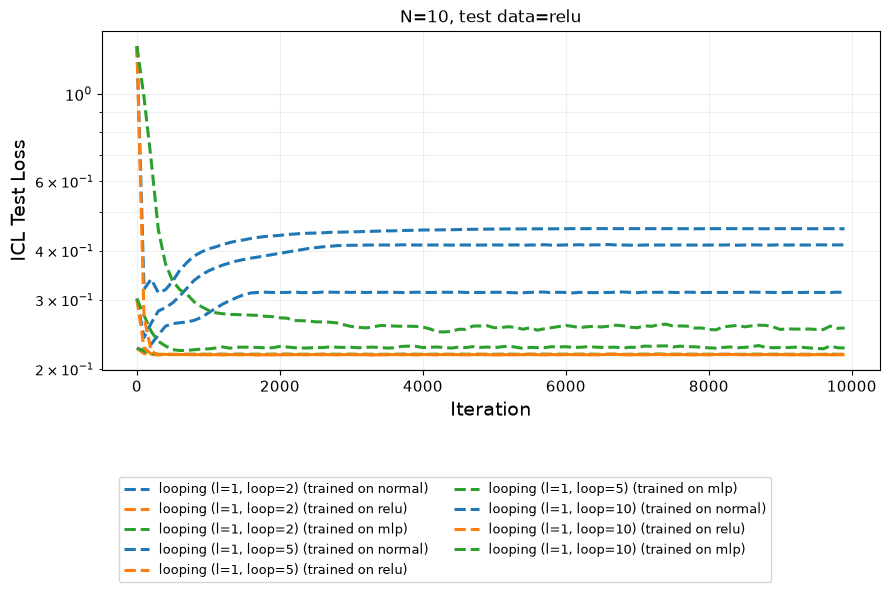

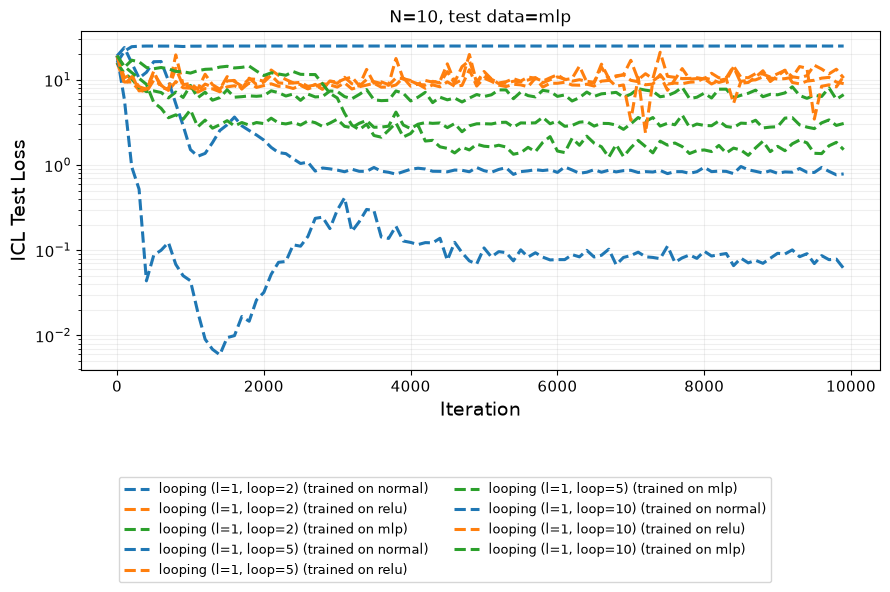

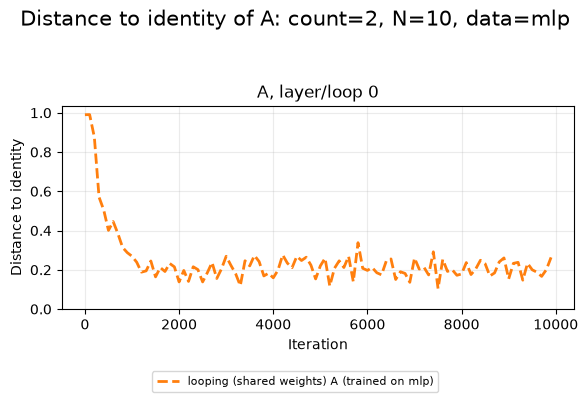

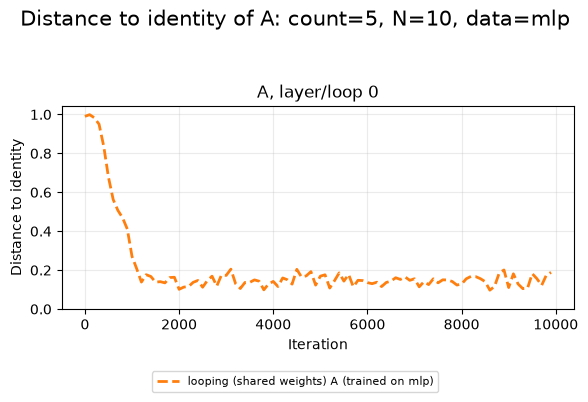

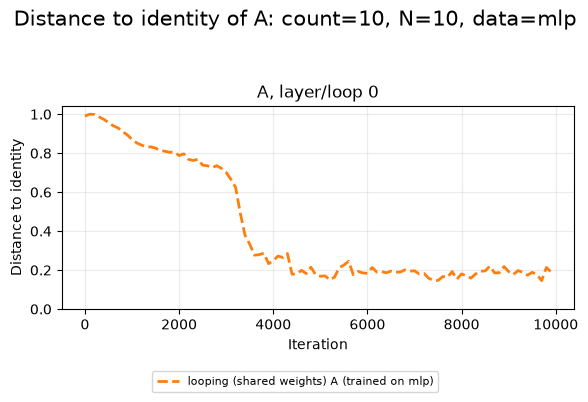

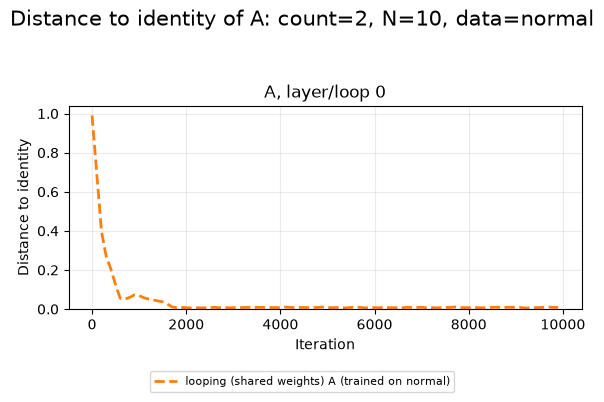

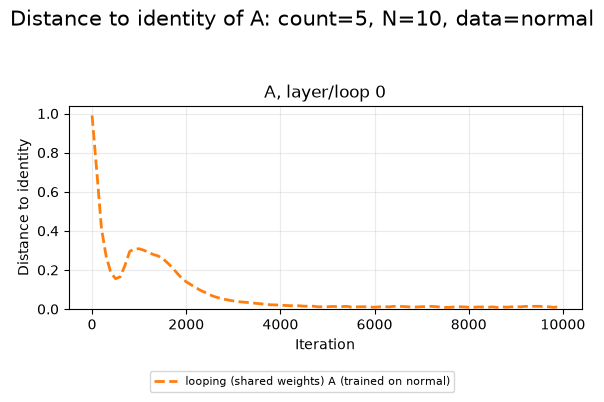

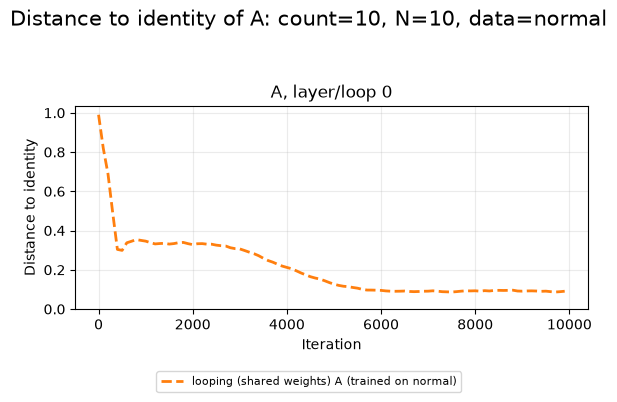

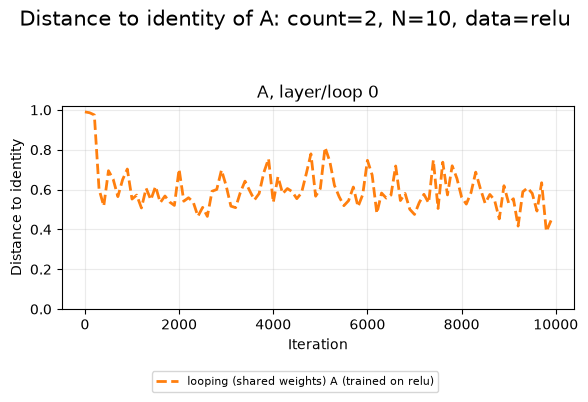

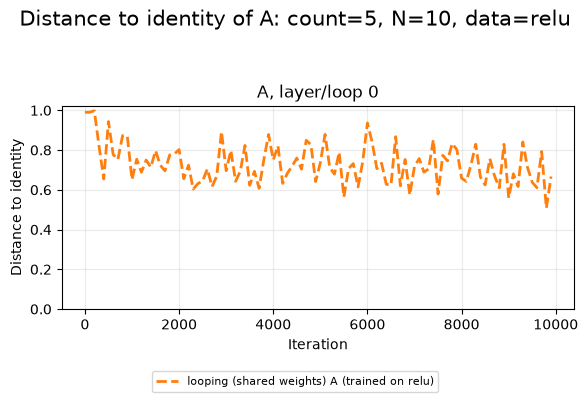

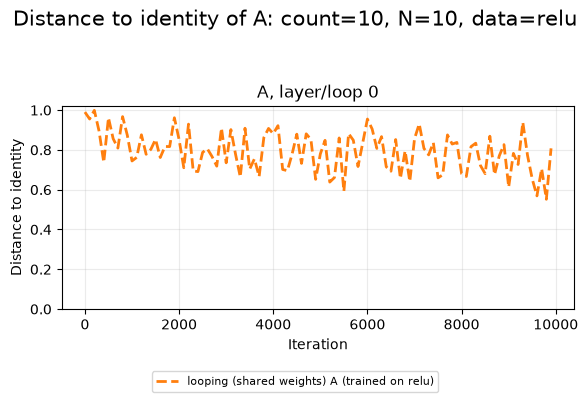

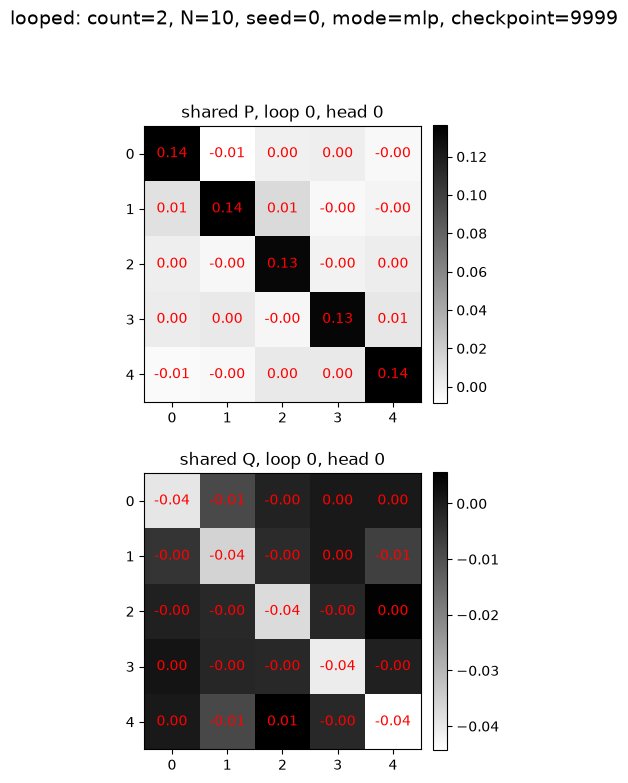

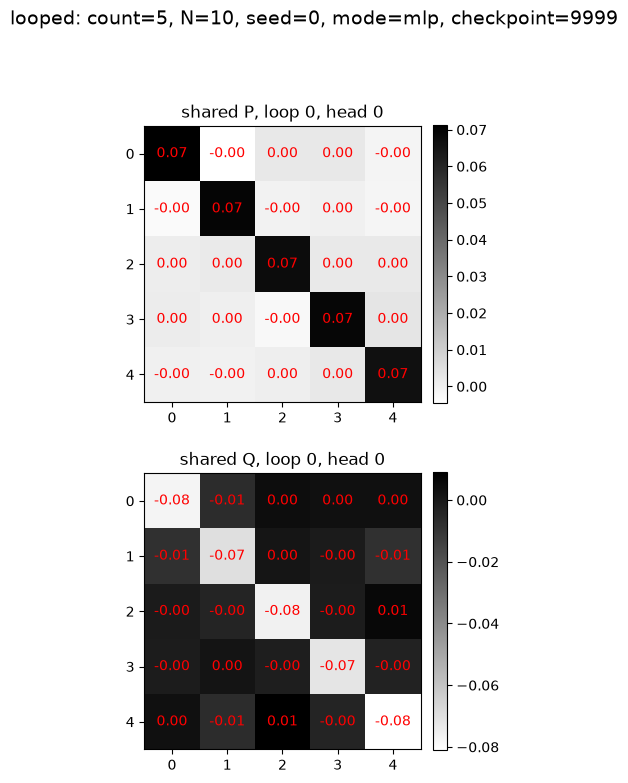

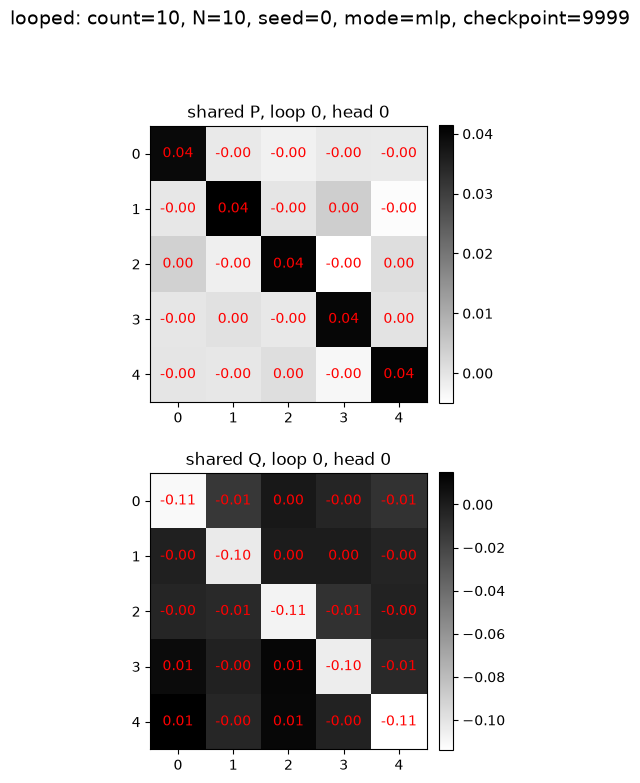

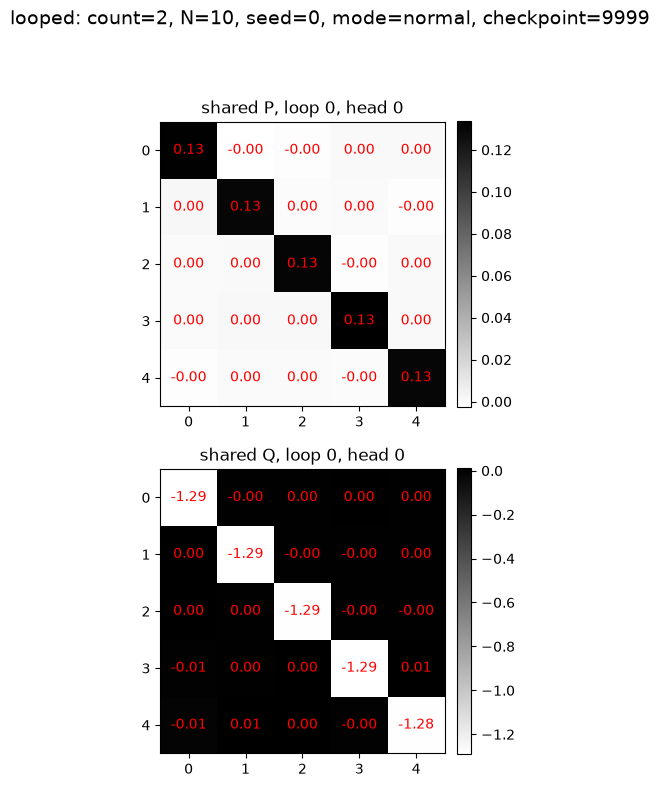

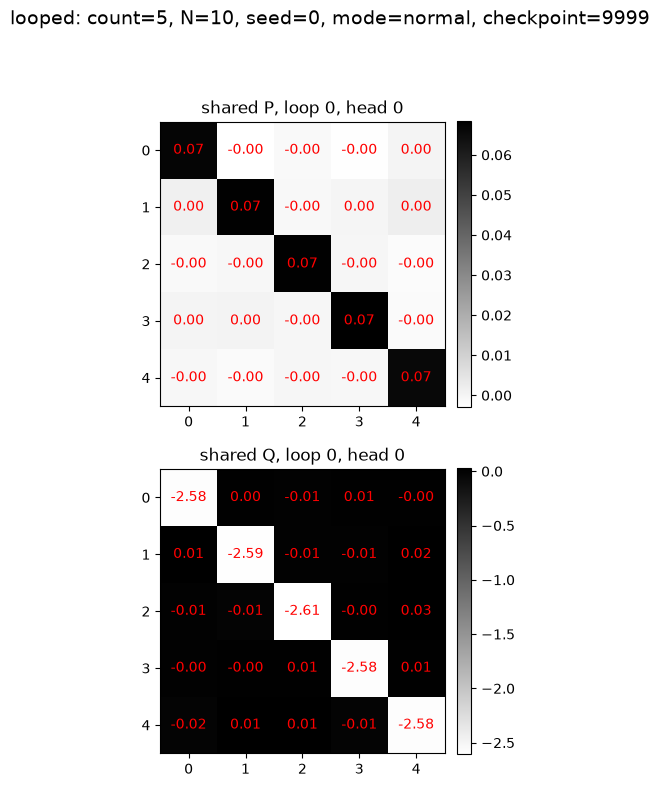

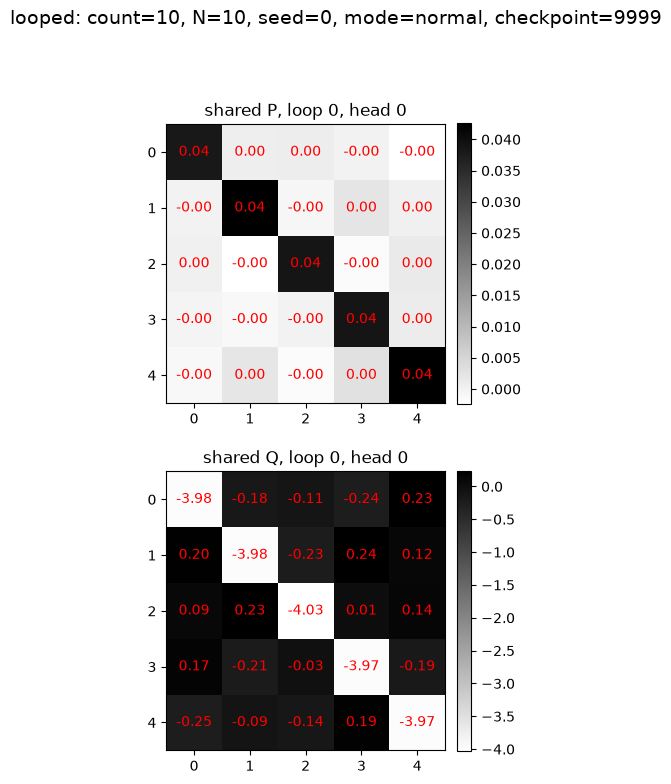

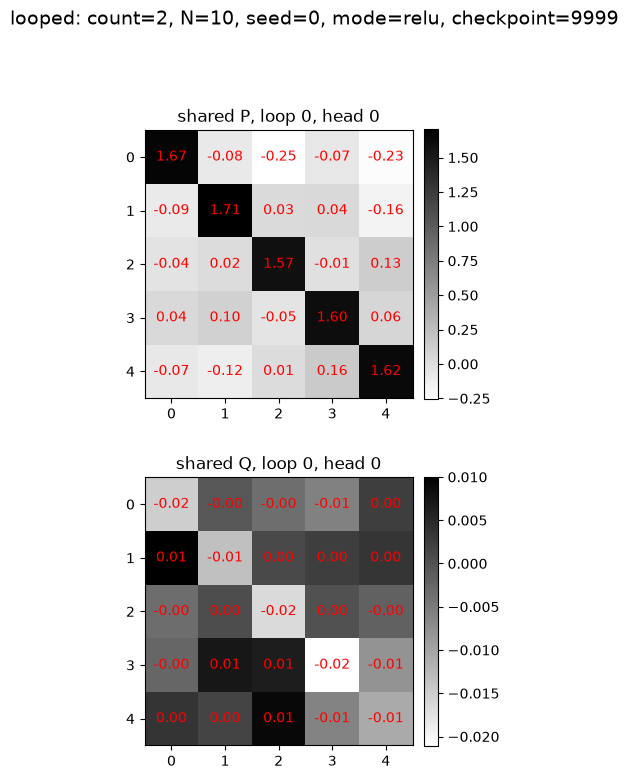

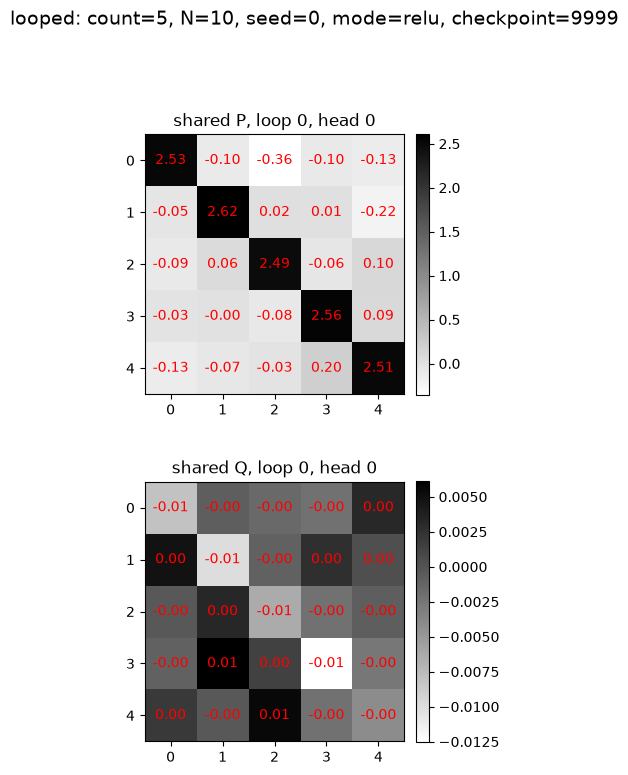

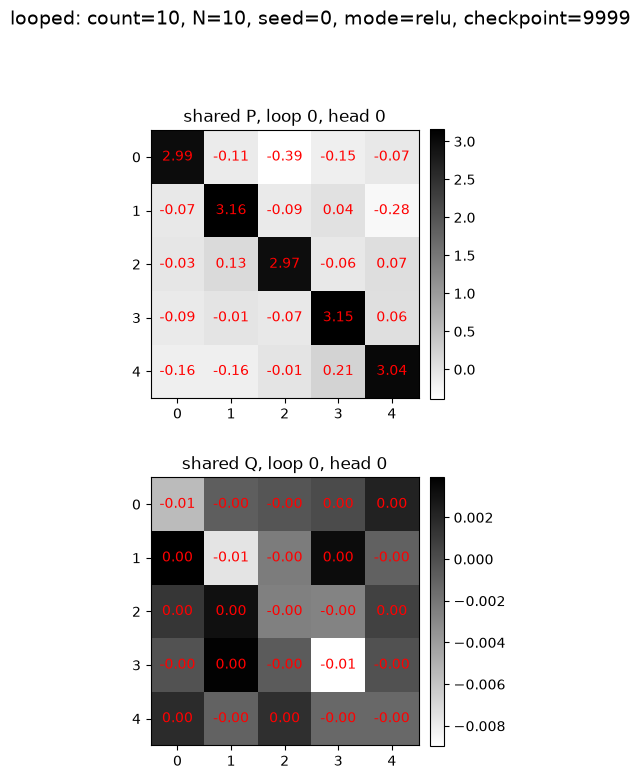

In [15]:
for test_data_mode, loss_dict in nonlinear_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=nonlinear_fig_dir,
        filename='nonlinear_data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    nonlinear_dist_dict, loop_counts, iterations, fig_dir=nonlinear_fig_dir,
)
plot_parameter_matrices(
    nonlinear_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=nonlinear_fig_dir,
)


# Multi-head looped transformer sweep

Train only the shared-weight looped transformer on the same Gaussian regression task while sweeping the number of attention heads over [1, 2, 4, 8]. This mirrors the original depth/loop experiment, but now the architecture is allowed to vary in width instead of type. The run uses the same seeds, loop counts, context length, and training setup as the baseline, and stores the resulting histories and test losses for comparison across head counts.

In [22]:
# --- Multi-head looped transformer sweep ---

multihead_seeds = [0]
multihead_loop_counts = [2, 5]
multihead_model_types = ['looped']
multihead_head_counts = [1, 2, 4]
multihead_context_lengths = [N]
multihead_filename = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_histories.pth')
multihead_results_file = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_results.pth')

multihead_hist_dict = run_experiment_suite(
    seeds=multihead_seeds,
    n_layers_loops=multihead_loop_counts,
    model_types=multihead_model_types,
    filename=multihead_filename,
    context_lengths=multihead_context_lengths,
    data_modes=[normal_data_mode],
    head_counts=multihead_head_counts,
)

multihead_loss_dict = compute_loss_dict(
    multihead_hist_dict,
    test_seed=TEST_SEED,
    data_mode=normal_data_mode,
)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': multihead_seeds, 'loop_counts': multihead_loop_counts,
        'model_types': multihead_model_types, 'head_counts': multihead_head_counts,
        'context_lengths': multihead_context_lengths, 'data_mode': normal_data_mode,
        'test_seed': TEST_SEED,
    },
    'hist_dict': multihead_hist_dict,
    'loss_dict': multihead_loss_dict,
}, multihead_results_file)

print(f'Saved multi-head looped sweep results to {multihead_results_file}')


Run 1/6: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1
iter 0 | Loss: 5.184084415435791 | time: 0.004908323287963867 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.004140377044677734 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.004330873489379883 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.005481243133544922 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.004513263702392578 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.004328012466430664 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.004304170608520508 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.003993034362792969 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.003999948501586914 | gradnorm: 1.5670084953308105
iter 500 | Loss: 

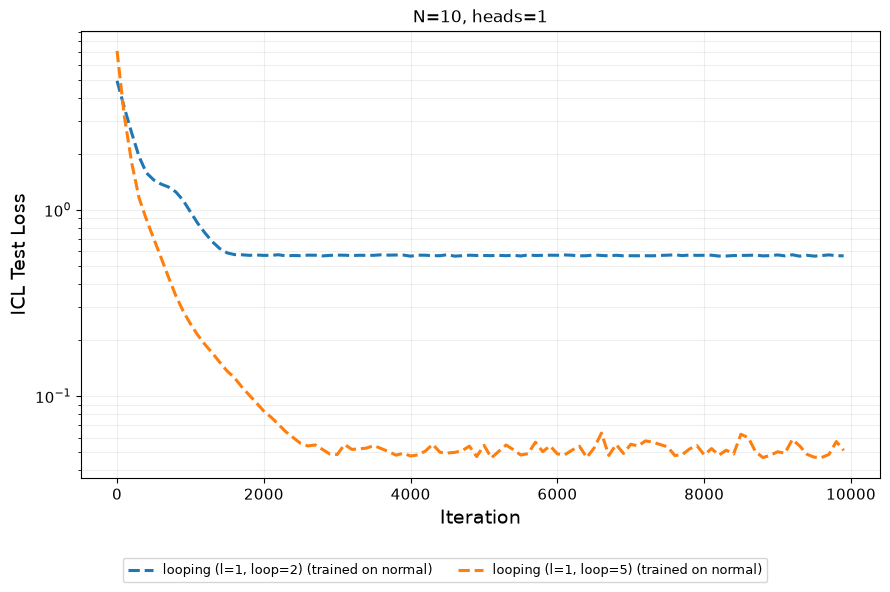

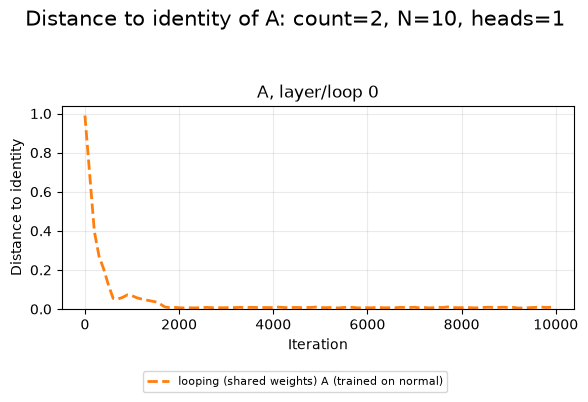

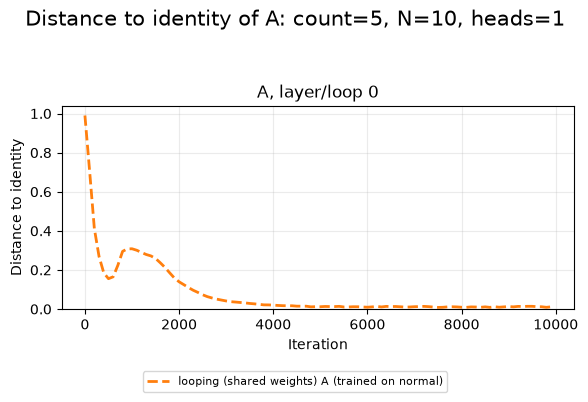

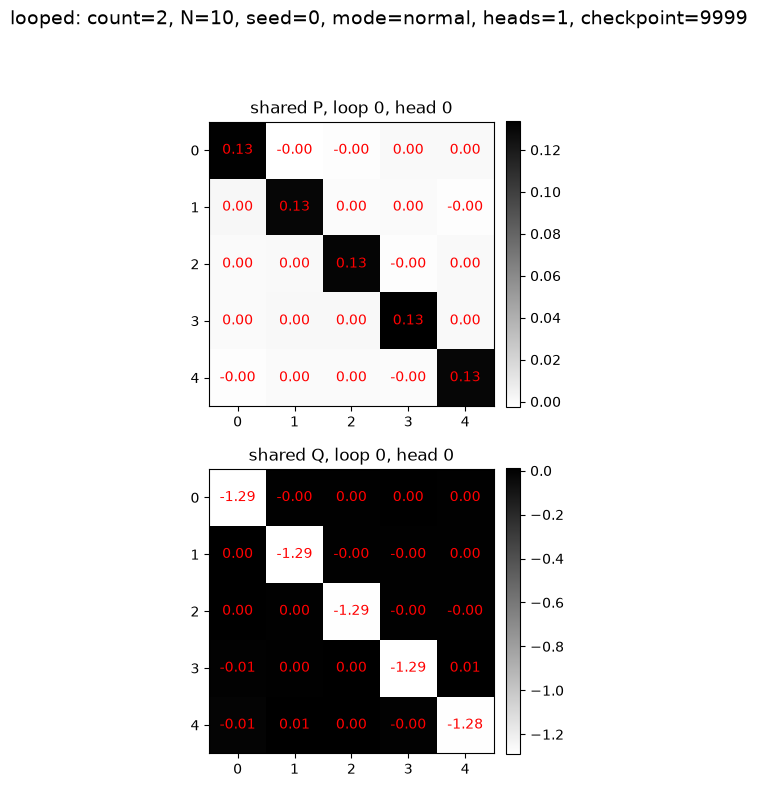

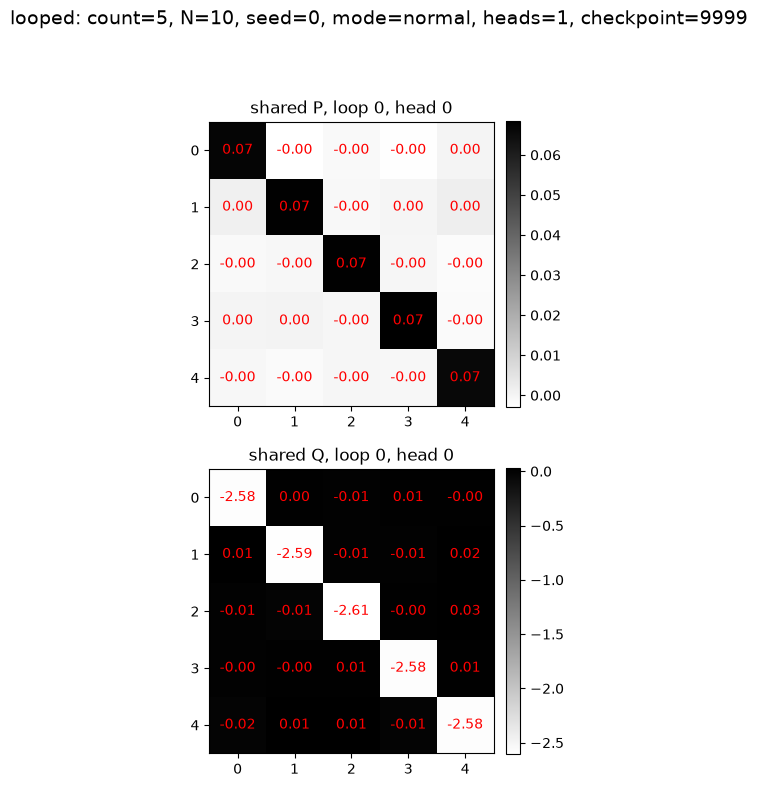

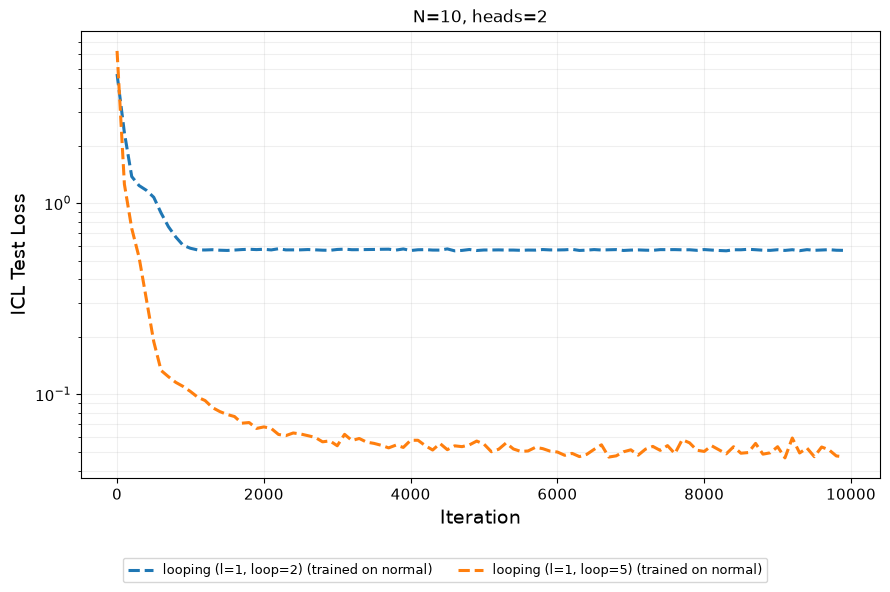

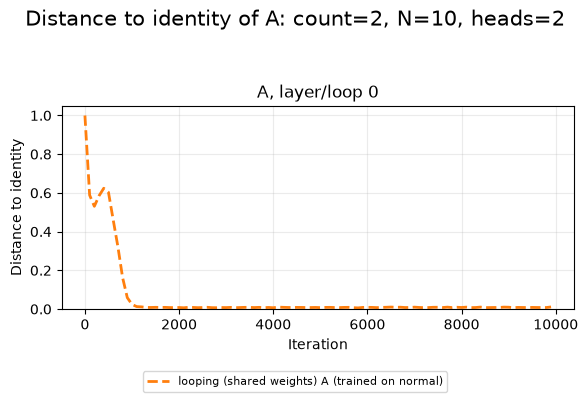

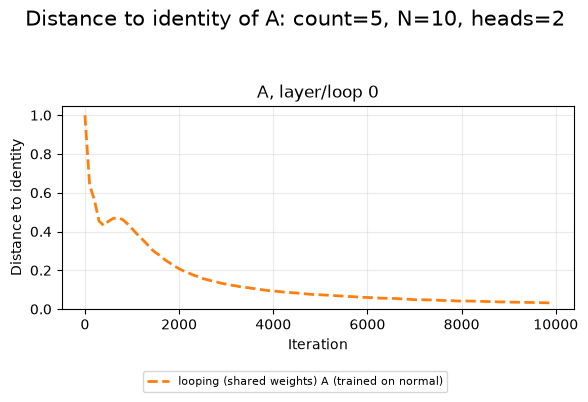

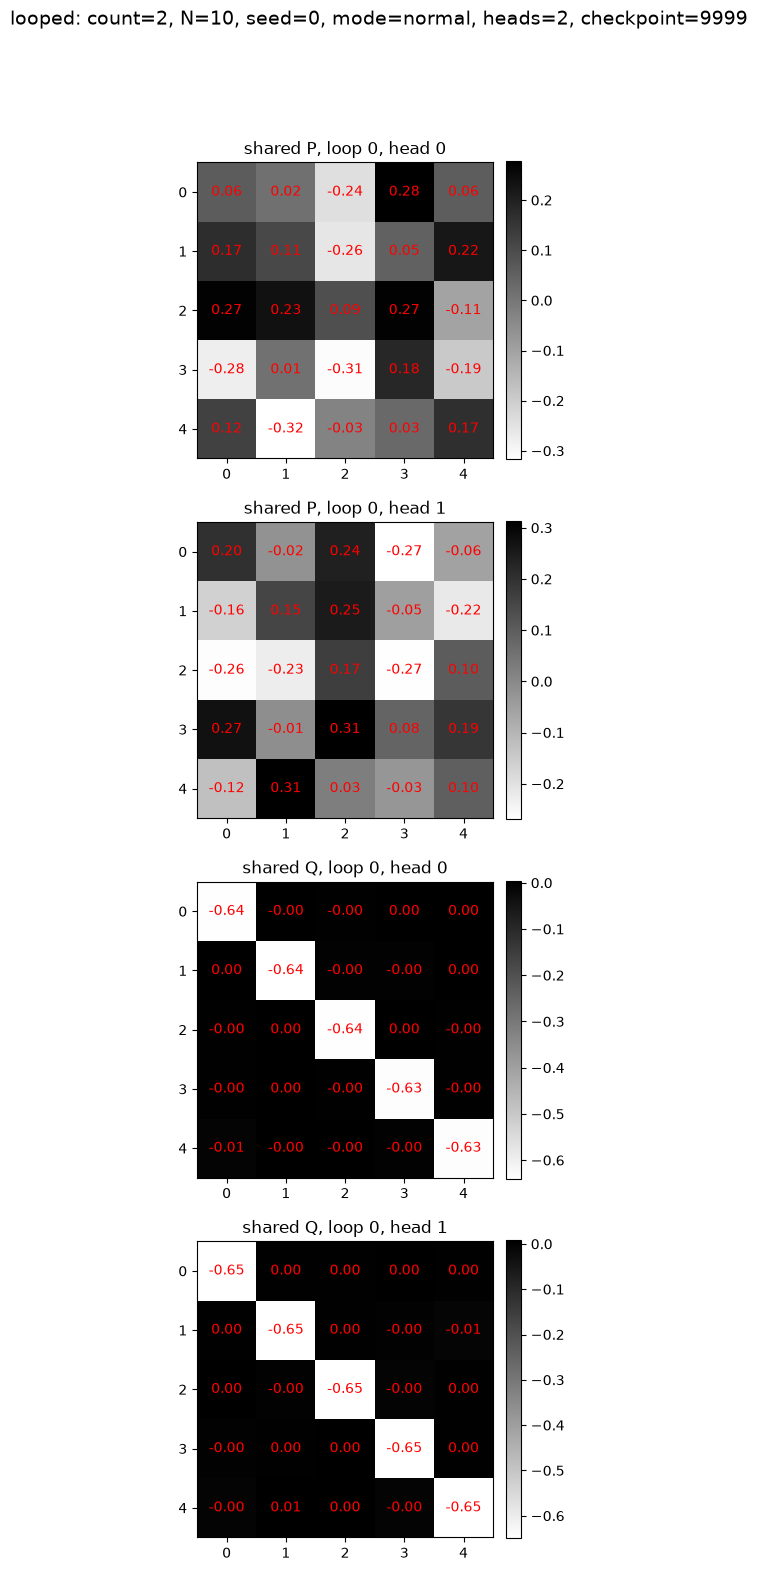

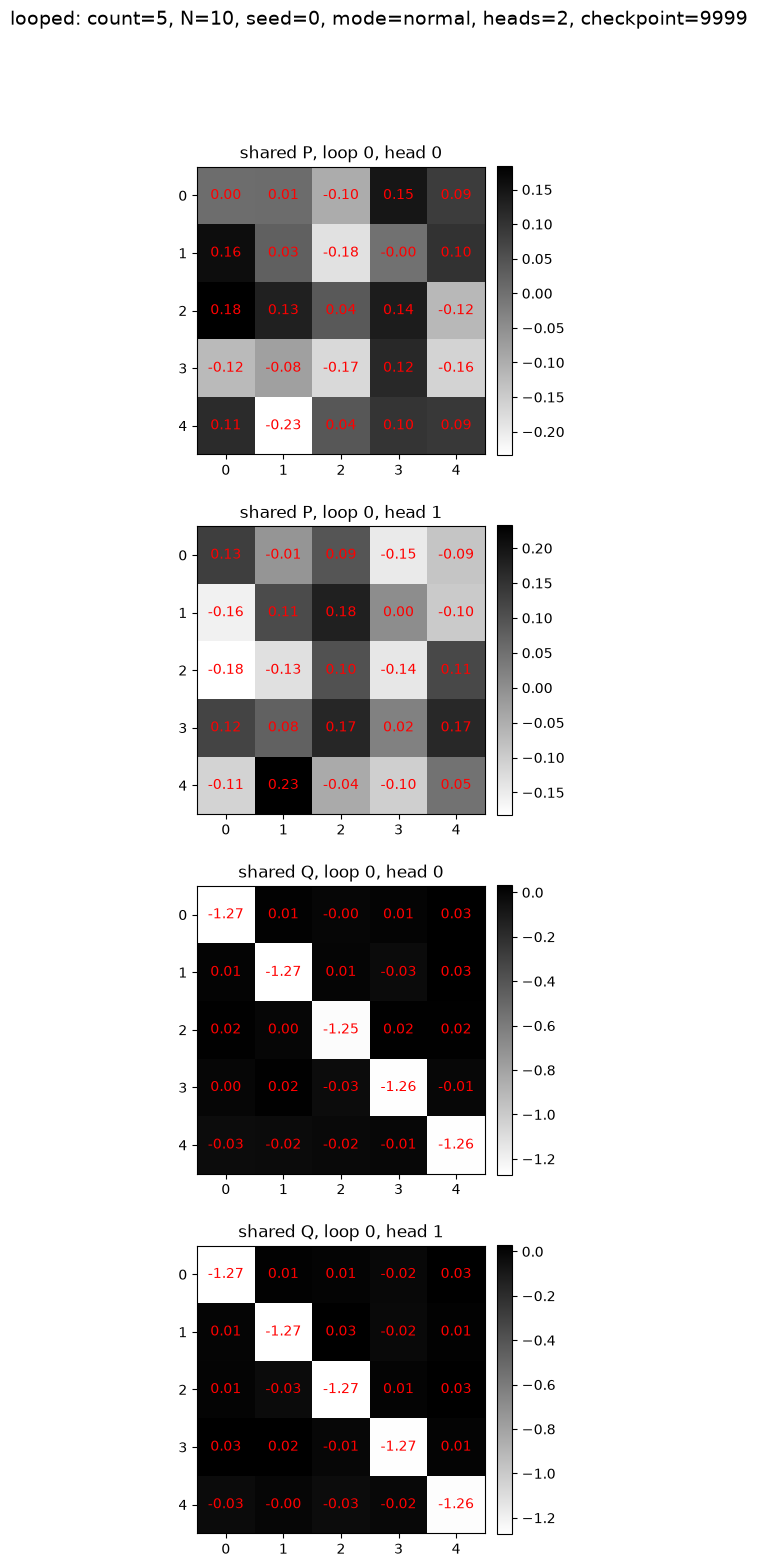

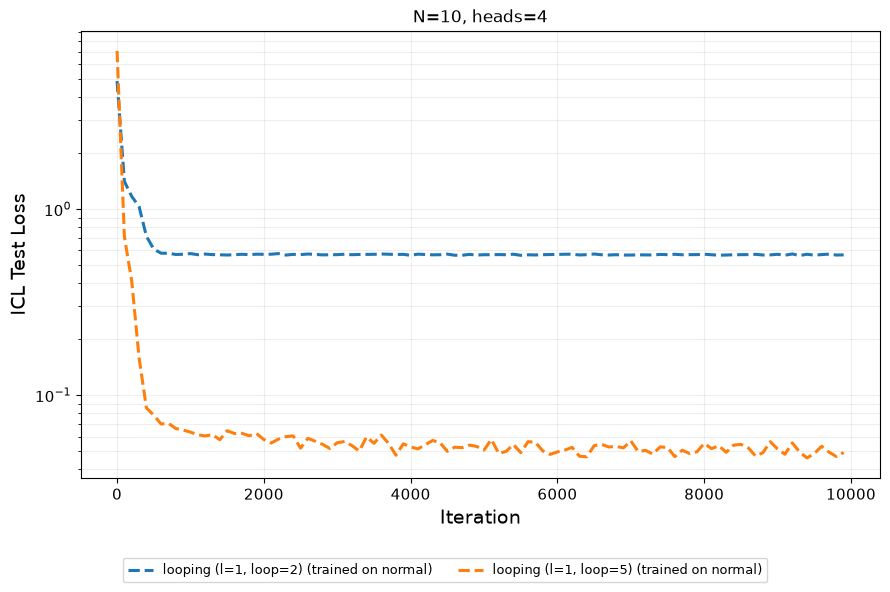

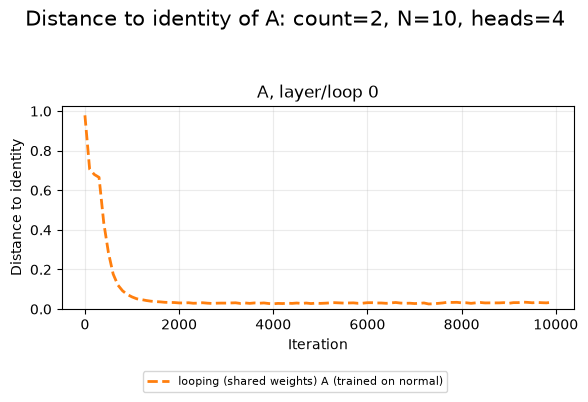

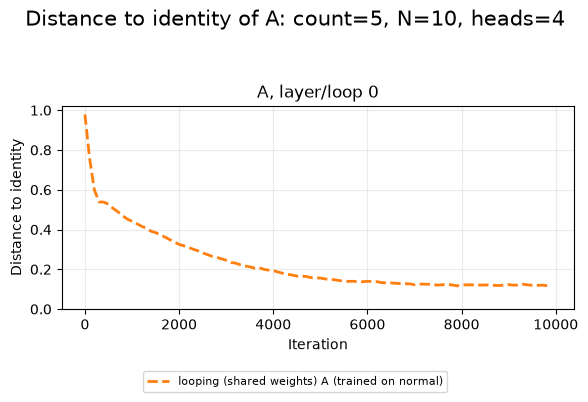

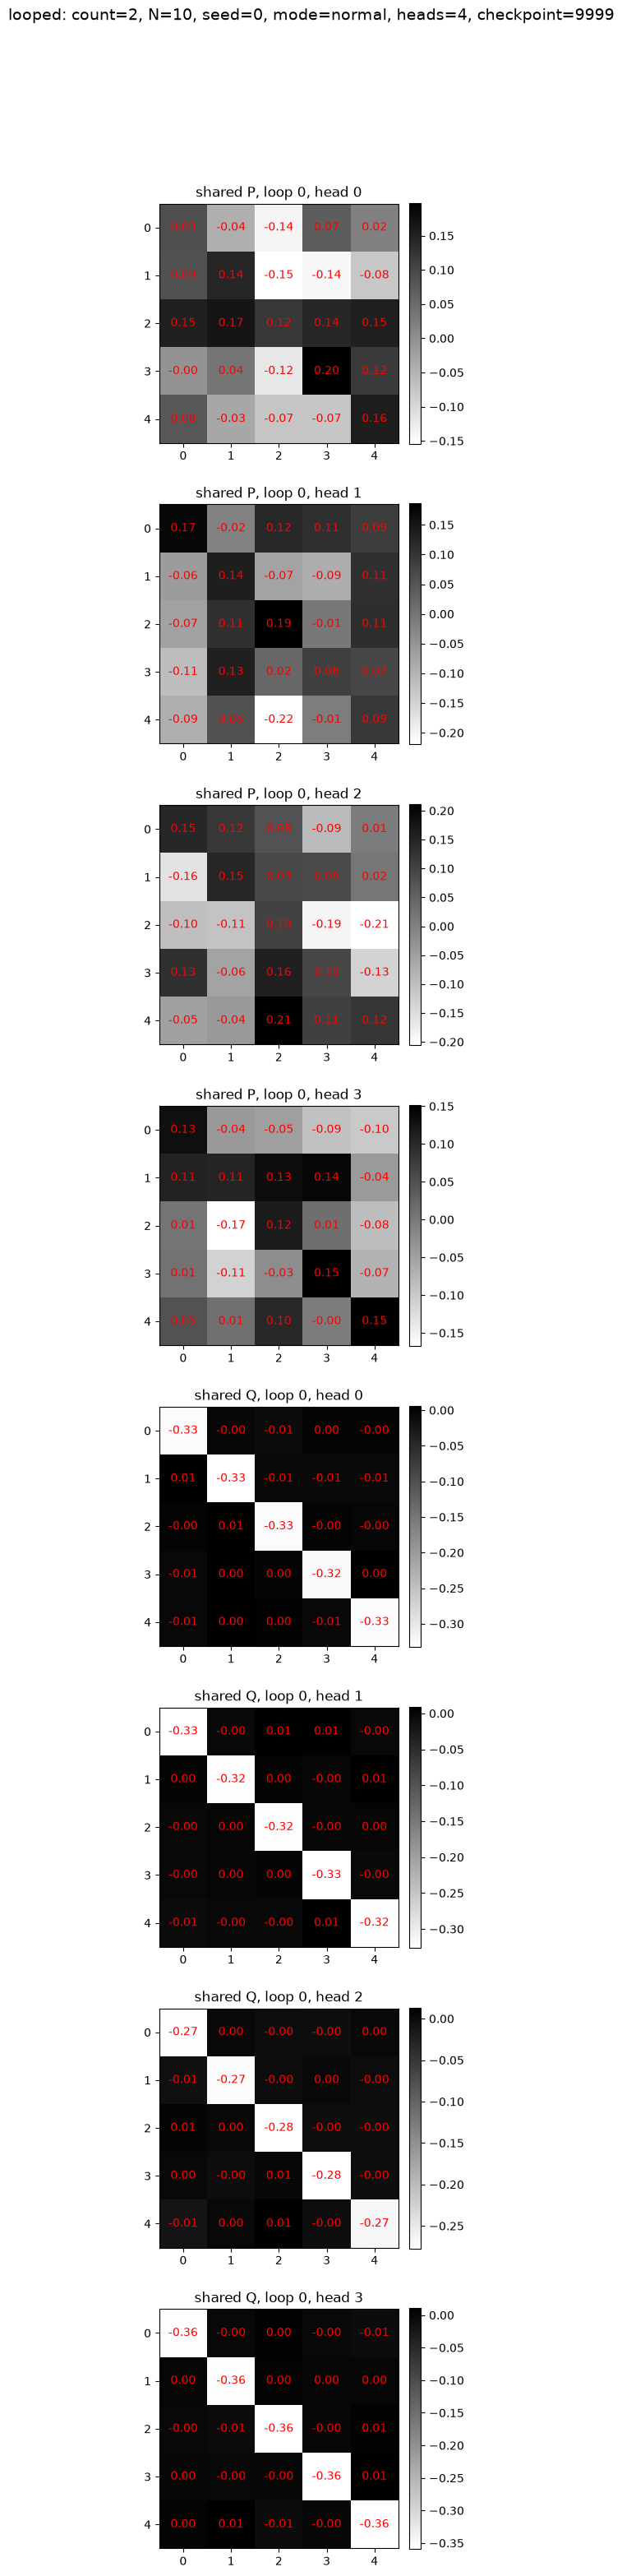

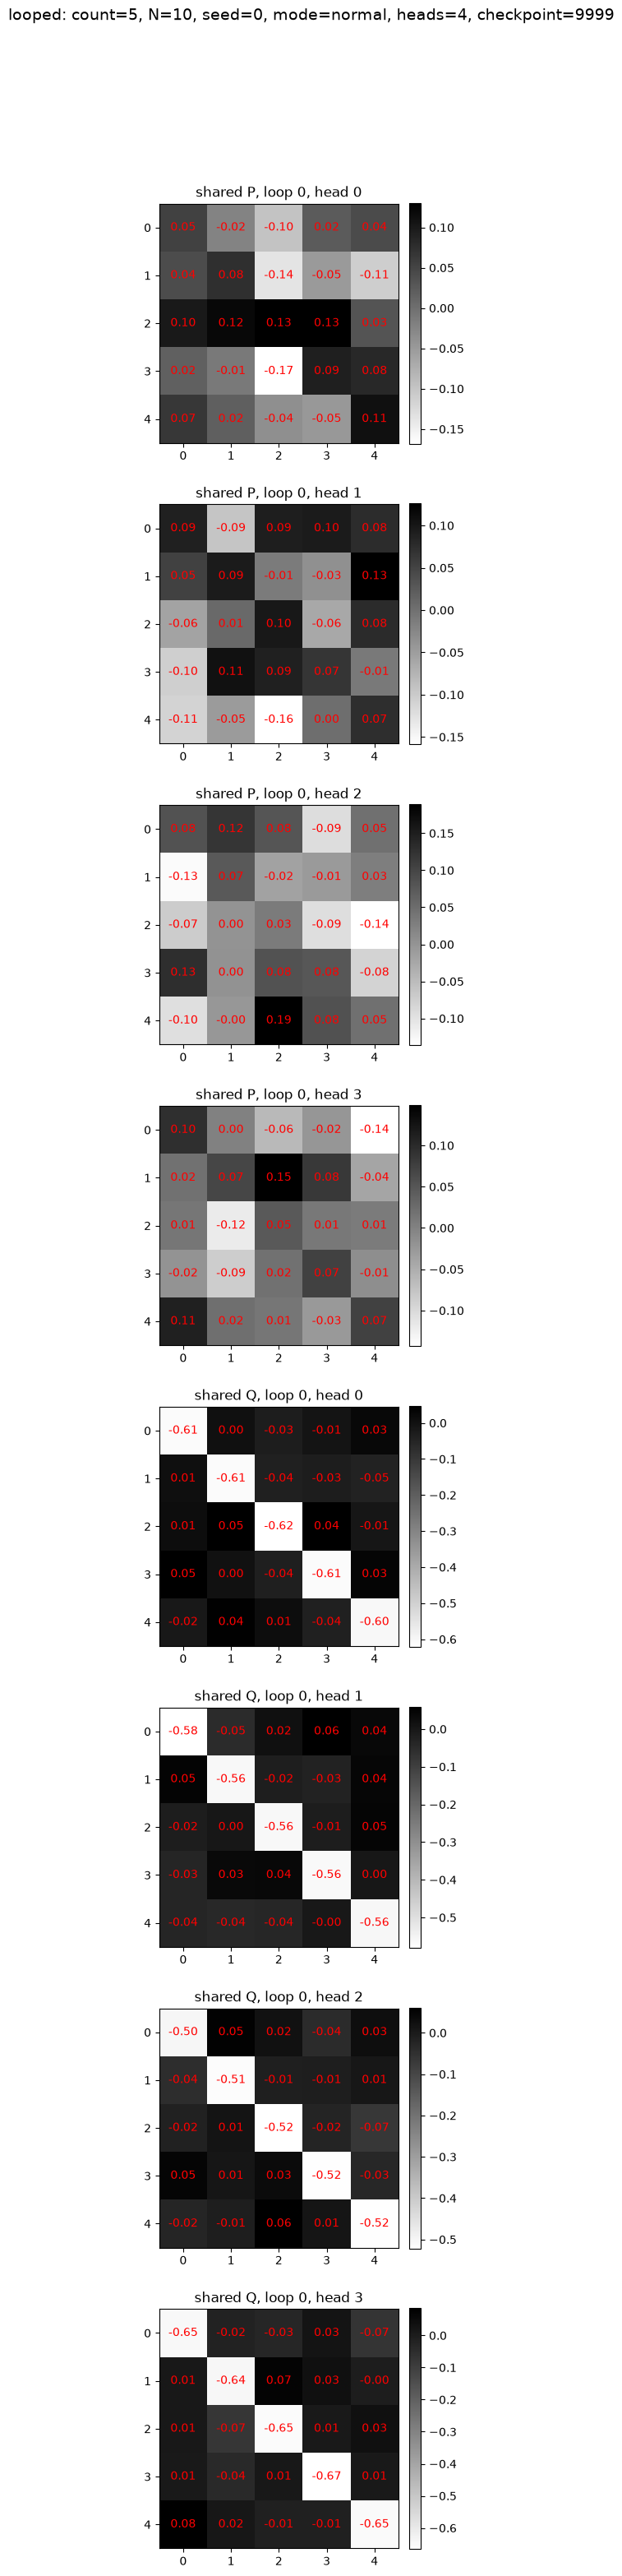

In [29]:
# Use the notebook's standard convergence, distance, and parameter plotting helpers.
multihead_plot_dir = os.path.join('figures', 'looped_multihead')
multihead_iterations = np.arange(0, max_iters, stride)

for head_count in multihead_head_counts:
    head_hist_dict = {
        key: history for key, history in multihead_hist_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_loss_dict = {
        key: losses for key, losses in multihead_loss_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_fig_dir = os.path.join(multihead_plot_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)

    plot_loss_curves(
        head_loss_dict,
        multihead_loop_counts,
        multihead_model_types,
        multihead_iterations,
        fig_dir=head_fig_dir,
        filename='held_out_loss.pdf',
        seeds=multihead_seeds,
        head_count=head_count,
    )

    head_dist_dict = compute_dist_dict(
        head_hist_dict,
        multihead_iterations,
        n_head=head_count,
        hist_stride=hist_stride,
    )
    plot_dist_to_identity(
        head_dist_dict,
        multihead_loop_counts,
        multihead_iterations,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )

    plot_parameter_matrices(
        head_hist_dict,
        multihead_seeds[0],
        multihead_loop_counts,
        multihead_model_types,
        n_head=head_count,
        hist_stride=hist_stride,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )
